<div align="center">

# ⚡ Prometheus

**India's open-source energy intelligence platform.**
Transforms raw meter telemetry into decisions — forecasting demand, detecting theft,
optimising tariffs, and mapping grid carbon — at every scale from household to feeder.

<br/>

[![AI: LightGBM + BiLSTM + SARIMA](https://img.shields.io/badge/AI-LightGBM%20%2B%20BiLSTM%20%2B%20SARIMA-blue?style=flat-square)](/)
[![Backend: FastAPI](https://img.shields.io/badge/Backend-FastAPI-009688?style=flat-square)](/)
[![Frontend: React + Vite](https://img.shields.io/badge/Frontend-React%20%2B%20Vite-orange?style=flat-square)](/)
[![Region: India](https://img.shields.io/badge/Region-India%20%F0%9F%87%AE%F0%9F%87%B3-red?style=flat-square)](/)
[![Dataset: 2017–2025](https://img.shields.io/badge/Dataset-2017--2025-yellow?style=flat-square)](/)
[![States: All 36](https://img.shields.io/badge/States-All%2036-purple?style=flat-square)](/)
[![License: MIT](https://img.shields.io/badge/License-MIT-green?style=flat-square)](LICENSE)

<br/>

| 📊 5.28 Cr | 📉 < 25% | 💸 ₹1.32L Cr | 🗓️ 8 Years |
|:---:|:---:|:---:|:---:|
| Smart meters installed under RDSS (Dec 2025) | DISCOM smart meter data actually utilised | Annual electricity theft loss — the gap we fill | Hourly state-wise demand dataset (2017–2025) |

</div>

---

## Table of Contents

1. [Why Prometheus](#-why-prometheus)
2. [Problem Statement](#-problem-statement)
3. [Dataset](#-dataset)
4. [Model Portfolio](#-model-portfolio)
5. [Feature Tiers](#-feature-tiers)
6. [Architecture](#-architecture)
7. [Technology Stack](#-technology-stack)
8. [Data Sources](#-data-sources)
9. [Getting Started](#-getting-started)
10. [Evaluation Metrics](#-evaluation-metrics)
11. [Roadmap](#-roadmap)
12. [References](#-references)
13. [License](#-license)

---

## 🔥 Why Prometheus

India has deployed **5.28 crore smart meters at a cost of ₹3 lakh crore** under the Revamped Distribution Sector Scheme (RDSS). Yet fewer than one in four DISCOMs meaningfully utilise the data these meters generate. The Ministry of Power has explicitly mandated that AI/ML be deployed to detect theft and build actionable intelligence from smart meter data. **Prometheus is that analytics layer.**

Beyond theft, the June 2023 ToD (Time-of-Day) tariff rules — now live for all non-agricultural consumers — create a **40% intra-day price spread** between solar hours (10 AM–6 PM) and peak hours (6 PM–10 PM). No consumer-facing tool translates this into rupee-level decisions. Prometheus does.

> **Context:** AT&C losses fell to a record **15.04%** in FY2024-25, yet remain more than double the global average of ~7% (IEA, 2021). Prometheus targets the commercial loss component — the part driven by undetected theft, poor demand forecasting, and suboptimal load scheduling.

---

## 📋 Problem Statement

This hackathon provides **six years of hourly electricity consumption data** (we have eight, 2017–2025) representing a multivariate time series with clear daily, weekly, and yearly seasonality, as well as state-level heterogeneity, festival spikes, and weather-driven demand shifts.

> **The challenge:** Design and implement ML/DL solutions that capture temporal dependencies, seasonality, and trends; handle missing values, noise, and unexpected fluctuations; deliver accurate predictions; *and* provide interpretability and actionable insights — not just a loss metric.

### What participants must deliver

1. Explore and understand the dataset — identify patterns, trends, and anomalies
2. Preprocess data including missing value imputation and outlier handling
3. Engineer relevant features (time-based, weather-based, India-specific calendar features)
4. Select and justify forecasting model(s) with architecture rationale
5. Train and validate on historical data with temporal cross-validation
6. Evaluate using MAE, RMSE, and MAPE
7. Present insights and explain model behavior (SHAP, partial dependence)

### Expected outputs

- Working forecasting model(s) predicting hourly energy demand
- Visual comparison of actual vs predicted values (by state, by season)
- Performance metrics table across all models
- Insights into consumption trends and model behavior

### Suggested approaches (from problem statement)

> Participants may explore models such as **ARIMA, SARIMA, Prophet, LSTM,** or tree-based methods like **XGBoost**. Python libraries such as Pandas, NumPy, scikit-learn, TensorFlow, and PyTorch can be used. Visualization tools like Matplotlib or Power BI are recommended for presenting results.

Prometheus implements all of the above — and goes further with a multi-model ensemble, quantile uncertainty, and operational decision layers.

---

## 📦 Dataset

### Primary training dataset

State-wise hourly electricity demand for all Indian states and union territories, spanning **January 2017 – December 2025** (~70,000 rows per state, ~2.5M rows total).

| Column | Type | Description | Notes |
|--------|------|-------------|-------|
| `State` | Categorical | Indian state or UT name | 36 unique values; add region grouping as a feature |
| `Date` | Date | Calendar date (YYYY-MM-DD) | Parse with timezone = IST (UTC+5:30) |
| `Hour` | Integer 0–23 | Hour of day | Combine with Date → single datetime index |
| `Hourly Demand Met (in MW)` | Float | **Target variable** — actual demand served in MW | May contain zeros/nulls during outages; treat carefully |

### Weather enrichment (Open-Meteo)

Open-Meteo provides hourly historical weather for every Indian state capital (1979–present, free, no API key). The full variable set is large — we select based on energy relevance:

| Variable | Unit | Energy Relevance | Include? |
|----------|------|-----------------|----------|
| `temperature_2m` | °C | AC/heating load driver — strongest single predictor in summer | ✅ Primary |
| `apparent_temperature` | °C | Perceived heat (heat index) — often better than dry-bulb for AC | ✅ Primary |
| `relative_humidity_2m` | % | Humidity amplifies cooling load; affects evaporative cooler usage | ✅ Primary |
| `dewpoint_2m` | °C | Correlated with humidity; use one or the other to avoid collinearity | ⚠️ Optional |
| `shortwave_radiation` | W/m² | Drives solar generation offset; key for rooftop solar states | ✅ Primary |
| `direct_normal_irradiance` | W/m² | More precise solar for panel efficiency calculation | ⚠️ Optional |
| `wind_speed_10m` | km/h | Drives wind generation in Rajasthan, Gujarat, TN, AP | ✅ Primary |
| `cloud_cover` | % | Correlated with solar irradiance and cooling load | ⚠️ Optional |
| `precipitation` | mm | Monsoon drives sharp load drops (cooler, irrigation pumps off) | ✅ Primary |
| `soil_moisture_0_1cm` | m³/m³ | Proxy for agricultural pump load in agri-heavy states | ✅ Selected states |
| `et0_fao_evapotranspiration` | mm | Agricultural water stress — drives pump load in Punjab, Haryana, UP | ✅ Selected states |
| `vapour_pressure_deficit` | kPa | Heat stress index; correlated with cooling demand | ❌ Skip (use `apparent_temperature`) |
| `surface_pressure` | hPa | Minimal direct impact on residential load | ❌ Skip |
| `carbon_monoxide / nitrogen_dioxide` | μg/m³ | AQI proxies — no direct demand link | ❌ Skip |

> **Feature engineering tip:** Create `cooling_degree_hours = max(T − 18, 0)` and `heating_degree_hours = max(18 − T, 0)`. These are more directly correlated with AC/heater load than raw temperature.

### India-specific engineered features

| Feature | How to Build | Why It Matters |
|---------|-------------|----------------|
| `is_holiday` | India `holidays` Python lib — national + state level | Diwali, Holi, Eid drive ±30% demand swings |
| `days_to_holiday` | Signed distance to nearest holiday | Pre-holiday commercial surge; post-holiday drop |
| `is_ipl_match_day` | Join IPL fixture data (2017–2025, public) | Evening TV + AC load spike in match cities |
| `monsoon_phase` | Encode pre/active/post per state using IMD onset dates | Monsoon drops load 8–15% in most states |
| `agricultural_season` | Rabi/Kharif crop calendar by state | Irrigation pump load dominates rural feeders |
| `tod_window` | Encode: solar (10–18h) / peak (18–22h) / off-peak | Post-ToD tariff regime behavioral signal |
| `slab_proximity` | Monthly cumulative kWh vs. slab thresholds | Consumers near slab boundaries shift behavior |
| `lag_1h / lag_24h / lag_168h` | Shift target column | Hourly autocorrelation is extremely high |
| `rolling_mean_24h / 168h` | Rolling window on demand | Smooth seasonal baseline |
| `region` | Map state → North/South/East/West/NE/Central | Regional grid interconnection clusters |
| `cooling_degree_hours` | `max(temperature_2m − 18, 0)` | Direct AC load proxy |

---

## 🧠 Model Portfolio

We build **multiple specialised models** for distinct use cases — not a single monolithic predictor. Each model is justified by peer-reviewed research and serves a specific operational stakeholder.

---

### Model 01 — LightGBM Quantile Ensemble
**Horizon:** 24 hr & 7 day · **Stakeholder:** DISCOM operators, households

The primary forecaster for operational dispatch planning and consumer bill intelligence.

- Trained with `objective='quantile'` at `alpha = [0.1, 0.5, 0.9]` to produce P10/P50/P90 uncertainty bands natively
- SHAP explainability baked in — feature importance waterfall available per prediction
- Trains on the full 8-year dataset in < 10 min; inference in milliseconds
- Per-state models trained independently; state ID also used as a categorical feature in a global model
- Research basis: comparative study of XGBoost, LightGBM, LSTM, and ARIMAX demonstrated **LightGBM's superiority** in accuracy, execution speed, and handling non-linear patterns for energy forecasting *(ResearchGate, 2025)*

---

### Model 02 — Bidirectional LSTM
**Horizon:** 48 hr · **Stakeholder:** Grid operators, regional load despatch centres

Captures long-range temporal dependencies that tree models miss.

- BiLSTM architecture (forward + backward pass) — improves MAPE vs. vanilla LSTM
- Input: sliding window of 168 hours (1 week) → predict next 48 hours
- Trained with weather + demand multivariate input (temperature, humidity, radiation, lag features)
- Stacked with LightGBM P50 output in an ensemble meta-learner for best-of-both accuracy
- Genetic algorithm-based feature selection to reduce input dimensionality before training *(PLOS ONE, Jan 2025)*
- Research basis: BiLSTM + GRU ensembles with stacking showed consistent MAPE improvements over single sequence models

---

### Model 03 — SARIMA / Prophet Baseline
**Horizon:** 30 day · **Stakeholder:** Procurement teams, state-level planning

Interpretable statistical baselines that planners can read and regulators can audit.

- **SARIMA**: captures daily (s=24) + weekly (s=168) + annual seasonality with explicit parameterisation; tuned per state using `auto_arima`
- **Prophet**: handles Indian holiday effects (Diwali, Holi, Eid) and monsoon changepoints cleanly without custom feature engineering
- Serves as the **benchmark baseline** that all ML models must outperform — if LightGBM can't beat SARIMA on a given state, the ML model is not ready
- Fast to fit; useful for states with limited smart meter rollout (Kerala, Karnataka)
- Used to generate synthetic demand profiles for states with data gaps, for training augmentation

---

### Model 04 — Isolation Forest + Theft Risk Scorer
**Horizon:** Real-time · **Stakeholder:** DISCOM field engineers, vigilance teams

Unsupervised anomaly detection aligned with the Ministry of Power's explicit mandate.

- Isolation Forest on rolling 15-min/hourly consumption windows; `contamination = 0.05`
- **Theft Risk Index (0–100):** composite of Z-score of consumption vs. DT-level benchmark (30%), anomaly frequency in last 30 days (25%), billing gap ratio (25%), and reverse flow detection (20%)
- Explains anomalies in plain English — rule-based cause mapping (theft, equipment fault, simultaneous load, meter tamper)
- Feeder-level heat map output rendered in Leaflet.js for field inspection prioritisation
- Research basis: The Ministry of Power stated that *"AI/ML would be leveraged to analyse data generated through smart meters to detect theft cases and prepare actionable MIS"* *(PIB, 2023)*

---

### Ensemble Meta-Learner

LightGBM (P50 output) + BiLSTM predictions are stacked with a linear meta-learner trained on a rolling holdout set. Weights are recomputed every 7 days based on recent rolling MAE per state.

> **Research basis:** TCN-LSTM + LightGBM ensemble reduced MAE by **4.88%** vs. the sequence model alone and **28.95%** vs. LightGBM alone on load forecasting benchmarks *(ScienceDirect, 2025)*.

---

## 🏗️ Feature Tiers

### Tier 1 — MVP (builds in 24 hours)

| Feature | Description |
|---------|-------------|
| **24hr + 7-day Forecast** | Hourly demand prediction with P10/P50/P90 confidence bands. State-selectable. |
| **Slab + ToD Cost Engine** | kWh → ₹ conversion using live tariff configs for MSEDCL, BESCOM, PGVCL, TNEB, DHBVN. |
| **Anomaly Detection** | Isolation Forest on rolling windows. Plain-language cause explanation in English + Hindi. |
| **Theft Risk Scorer** | Composite 0–100 index per feeder. Leaflet heat map. Prioritised inspection list output. |
| **ToD Shift Recommendations** | Appliance-level shift suggestions ranked by ₹/month saved under ToD regime. |

### Tier 2 — Advanced (medium complexity)

| Feature | Description |
|---------|-------------|
| **Quantile Uncertainty Bands** | P10/P90 from LightGBM quantile regression. Low-confidence alert when spread > 30%. |
| **Feeder Aggregate Forecast** | Bottom-up rollup: consumer → DT → feeder → substation. Uncertainty propagated upward. |
| **Solar Prosumer Optimiser** | PM Surya Ghar users get optimal self-consumption vs. export timing under net metering reform. |
| **SHAP Explainability Panel** | Feature importance waterfall charts per prediction. Which variables drove this forecast? |

### Tier 3 — Innovation (win-the-hackathon differentiators)

| Feature | Description |
|---------|-------------|
| **ONNX Edge Module** | LightGBM → ONNX (2MB). Runs offline on AMI concentrators or Raspberry Pi. MQTT sync. |
| **Carbon Intensity Tracker** | Hourly gCO₂/kWh from Ember + ElectricityMaps. Green Hours scheduling. Scope 2 reports. |
| **Demand Response Auction** | VPP micro-auction over WebSocket. Prosumer bids clear in real-time. Hash-chained audit log. |

---

## 🏛️ Architecture

### System flow

```mermaid
flowchart TD
    A[Smart Meter Telemetry\nState × Hour × MW] --> B[Feature Pipeline]
    W[Open-Meteo Weather API\nHourly · Free · No key] --> B
    C[India Calendar + Tariff DB\nHolidays · ToD · Slabs] --> B

    B --> D{Multi-Model Core}

    D --> M1[LightGBM Quantile\n24hr / 7-day forecast]
    D --> M2[BiLSTM Encoder\n48hr sequence model]
    D --> M3[SARIMA / Prophet\n30-day planning baseline]
    D --> M4[Isolation Forest\nAnomaly + theft risk]

    M1 --> E[Ensemble Meta-Learner\nRolling-weight stacking]
    M2 --> E

    E --> F[FastAPI Service Layer]
    M3 --> F
    M4 --> F

    F --> G[Household Dashboard\n₹ forecast · ToD tips]
    F --> H[MSME Dashboard\nLoad shift · demand charges]
    F --> I[DISCOM Ops View\nFeeder map · theft risk · auction]
```

### Module breakdown

```
Prometheus/
├── ingestion/
│   ├── meter_loader.py          # State × Hour × MW CSV ingestion
│   ├── weather_fetcher.py       # Open-Meteo API join on state capitals
│   └── tariff_configs/          # JSON tariff configs: MSEDCL, BESCOM, PGVCL, TNEB, DHBVN
│
├── features/
│   ├── calendar.py              # India holidays, IPL fixtures, monsoon phases, agricultural seasons
│   ├── weather_features.py      # CDH, HDH, radiation aggregates, monsoon flag
│   ├── lag_features.py          # t-1, t-24, t-168 lags + rolling means
│   └── tod_encoding.py          # Solar / peak / off-peak window labels + slab proximity
│
├── models/
│   ├── lgbm_quantile.py         # LightGBM P10/P50/P90 — primary forecaster
│   ├── bilstm.py                # Bidirectional LSTM — 48hr sequence model
│   ├── sarima_prophet.py        # Statistical baselines — benchmark + planning
│   ├── isolation_forest.py      # Anomaly detection + theft risk index
│   └── ensemble.py              # Linear meta-learner — dynamic rolling weights
│
├── backend/
│   ├── main.py                  # FastAPI app + WebSocket auction endpoint
│   ├── routers/
│   │   ├── forecast.py          # POST /forecast
│   │   ├── anomaly.py           # POST /anomaly
│   │   ├── tariff.py            # POST /tariff
│   │   ├── recommendations.py   # GET  /recommendations
│   │   ├── carbon.py            # GET  /carbon
│   │   ├── theft.py             # POST /theft-score
│   │   └── auction.py           # WS   /auction/live
│   └── schemas.py               # Pydantic v2 request/response models
│
├── frontend/
│   ├── src/
│   │   ├── views/
│   │   │   ├── Household.jsx    # Bill forecast · ToD savings · anomaly cards
│   │   │   ├── MSME.jsx         # Load shift optimizer · demand charge calculator
│   │   │   └── DISCOM.jsx       # Feeder heatmap · theft list · DR auction
│   │   └── components/
│   │       ├── ForecastChart.jsx    # Recharts AreaChart with confidence bands
│   │       ├── ToDClock.jsx         # 24-hour ToD tariff clock widget
│   │       ├── FeederMap.jsx        # Leaflet heatmap
│   │       └── AuctionFeed.jsx      # WebSocket live auction display
│
└── edge/
    ├── infer.py                 # ONNX Runtime inference — no cloud required
    └── mqtt_sync.py             # Delta sync via Mosquitto when connectivity available
```

### API endpoint reference

```
POST /forecast          →  7-day hourly prediction + P10/P50/P90 uncertainty bands
POST /anomaly           →  Isolation Forest detection + rule-based plain-English explanation
GET  /recommendations   →  ToD shift suggestions ranked by ₹/month savings
POST /tariff            →  kWh → ₹ for any Indian state tariff config
GET  /carbon            →  Carbon intensity + Green Hours by state
POST /theft-score       →  Feeder-level Theft Risk Index (0–100)
GET  /solar-optimise    →  Rooftop solar export/self-consumption schedule
WS   /auction/live      →  WebSocket demand response auction real-time feed
GET  /explain/{pred_id} →  SHAP waterfall chart for a specific forecast
```

---

## 🛠️ Technology Stack

### ML Layer

| Component | Choice | Justification |
|-----------|--------|---------------|
| Primary forecaster | **LightGBM** | Fastest training, native quantile regression, SHAP-native, outperforms LSTM on tabular energy data |
| Sequence model | **BiLSTM (PyTorch)** | Captures long-range temporal dependencies; BiLSTM outperforms vanilla LSTM on energy benchmarks |
| Statistical baseline | **SARIMA + Prophet** | Interpretable; handles Indian holiday effects; required benchmark |
| Anomaly detection | **Isolation Forest** | Unsupervised; no labeled theft data needed; production-proven |
| Ensemble | **Linear stacking** | Dynamic rolling-weight meta-learner; provably reduces error vs. any single model |
| Edge export | **ONNX Runtime** | 2MB model; ARM-compatible; <50ms inference; runs offline |
| Explainability | **SHAP** | Model-agnostic; waterfall charts per prediction for non-technical users |
| Feature selection | **tsfresh + GA** | Automated temporal feature extraction + genetic algorithm selection |

### Full stack

| Layer | Technologies |
|-------|-------------|
| **ML** | LightGBM, PyTorch, statsmodels, Prophet, scikit-learn, ONNX Runtime, SHAP, tsfresh |
| **Data** | Pandas, NumPy, India `holidays` lib, SQLite, Pydantic v2 |
| **Backend** | FastAPI, Uvicorn, WebSockets, Mosquitto MQTT |
| **Frontend** | React 18, Vite, Tailwind CSS, Recharts, Leaflet.js, React Query |
| **External APIs** | Open-Meteo (free), Ember CC-BY, ElectricityMaps (free tier), NITI ICED, Grid-India NLDC |
| **Deployment** | Vercel (frontend), Render.com (API) — **total infra cost: ₹0** |

> **Zero infra cost:** The complete stack deploys for ₹0. Open-Meteo is free with no API key. Ember data is CC-BY-4.0. ElectricityMaps free tier allows 1 request/hour per location — sufficient for the carbon intensity feature. Render and Vercel free tiers handle hackathon traffic comfortably.

---

## 📡 Data Sources

| Dataset / API | Source | License | Typical Use |
|---------------|--------|---------|-------------|
| **State-wise India Power Consumption (2019–2024)** | Kaggle (`twinkle0705`) | Free | Baseline training; state-level daily demand |
| **Electricity Load Forecasting** | Kaggle (`saurabhshahane`) | Free | Hourly Indian load data with weather labels |
| **Open-Meteo Historical Weather** | [open-meteo.com](https://open-meteo.com) | Free, no key | Hourly weather enrichment for all 36 state capitals |
| **Ember India Electricity Data** | [ember-energy.org](https://ember-energy.org/data/india-electricity-data/) | CC-BY-4.0 | State-level generation (GWh), carbon intensity (gCO₂/kWh) |
| **NITI ICED Hourly Load Profile** | [iced.niti.gov.in](https://iced.niti.gov.in/energy/electricity/distribution/national-level-consumption/load-curve) | Free, public | Regional/state hourly load profiles for validation |
| **Grid-India / NLDC Daily Reports** | [posoco.in](https://posoco.in/en/reports/daily-reports/) | Free, public | National demand ground truth; forecasting benchmark |
| **ElectricityMaps API** | [electricitymaps.com](https://www.electricitymaps.com) | Free tier (1 req/hr) | Near real-time carbon intensity for Green Hours feature |
| **UCI Household Electric Power** | UCI ML Repository | Free | Household-level training proxy; scale ×0.6 for India |
| **India DISCOM Tariff Orders** | State SERC websites | Public | Slab boundaries, ToD multipliers — MSEDCL, BESCOM, PGVCL, TNEB, DHBVN |
| **IPL Fixture Data (2017–2025)** | Kaggle / Cricsheet | Free | `is_ipl_match_day` feature for evening load spikes |
| **IMD Monsoon Onset Dates** | India Meteorological Dept | Public | `monsoon_phase` feature by state |

---

## 🚀 Getting Started

### Prerequisites

- Python 3.10+
- Node.js 18+ with `npm` or `pnpm`
- Git
- 8 GB RAM minimum (full 8-year training dataset in memory)

### Clone

```bash
git clone https://github.com/Purv-Kabaria/Prometheus.git
cd Prometheus
```

### Backend (FastAPI + ML)

```bash
# Create virtual environment
python -m venv .venv && source .venv/bin/activate  # Windows: .venv\Scripts\activate

# Install dependencies
pip install -r backend/requirements.txt

# Train all models (full 2017–2025 dataset, ONNX export included)
python backend/train.py --all-states --export-onnx

# Start API server
uvicorn backend.main:app --reload --port 8000
```

### Frontend (React + Vite)

```bash
cd frontend
npm install
npm run dev
# Open http://localhost:5173
```

### Edge module (offline ONNX inference demo)

```bash
# Run local inference — zero cloud dependency
python edge/infer.py \
  --model models/prometheus_lgbm.onnx \
  --state Maharashtra \
  --hours 24
```

---

## 📐 Evaluation Metrics

All models are evaluated on a **temporal holdout** (last 12 months of data, never seen during training) using expanding-window cross-validation. State-wise and season-wise breakdowns are reported separately.

| Metric | Formula | Target | Notes |
|--------|---------|--------|-------|
| **MAPE** | `mean(|y − ŷ| / y) × 100` | < 8% | Primary; scale-independent; comparable across states |
| **MAE** | `mean(|y − ŷ|)` | < 500 MW | Absolute MW; intuitive for grid operators |
| **RMSE** | `√mean((y − ŷ)²)` | < 800 MW | Penalises large errors; critical for peak forecasting |
| **Pinball Loss** | Quantile-weighted asymmetric error | Report P10/P90 | Measures calibration of uncertainty bands |
| **Coverage Rate** | % actuals inside P10–P90 | 80 ± 5% | A correctly calibrated interval should contain ~80% |
| **Anomaly F1** | Precision × Recall on synthetic injected anomalies | > 0.85 | Evaluated on held-out theft-pattern synthetic set |

> **Temporal CV protocol:** Use `TimeSeriesSplit(n_splits=5)` with a minimum gap of 48 hours between train and validation to prevent data leakage from lag features.

### Baseline comparison table (to be updated post-training)

| Model | MAPE | MAE (MW) | RMSE (MW) | Notes |
|-------|------|----------|-----------|-------|
| Naïve (same hour, last week) | ~15% | — | — | Lower bound baseline |
| SARIMA | TBD | TBD | TBD | Statistical benchmark |
| Prophet | TBD | TBD | TBD | Holiday-aware benchmark |
| LightGBM (global) | TBD | TBD | TBD | Primary model |
| BiLSTM | TBD | TBD | TBD | Sequence model |
| **Ensemble** | **TBD** | **TBD** | **TBD** | **Target: best overall** |

---

## 🗺️ Roadmap

### Phase 1 — Hackathon (Week 1)

- [x] Project structure and README
- [ ] Full data pipeline: 2017–2025 dataset + Open-Meteo join + India holiday features
- [ ] LightGBM quantile model trained per-state and globally
- [ ] BiLSTM trained on 168h sliding windows
- [ ] Prophet + SARIMA baselines for benchmark comparison
- [ ] Isolation Forest anomaly model + Theft Risk Index scorer
- [ ] FastAPI with all core endpoints
- [ ] React dashboard (Household + MSME + DISCOM role views)
- [ ] SHAP explainability panel
- [ ] ONNX export + local edge inference demo
- [ ] Carbon intensity + Green Hours feature (Ember + ElectricityMaps)
- [ ] Demand response auction simulation (WebSocket, 5 synthetic prosumers)

### Phase 2 — Post-hackathon hardening

- [ ] Productionise forecast retraining pipeline with distribution drift detection
- [ ] Feedback loop from DISCOM field inspection outcomes to anomaly model
- [ ] DPDPA (India Digital Personal Data Protection Act, 2023) compliance review
- [ ] Multi-tenant DISCOM onboarding with state-specific tariff management UI
- [ ] Publish model cards with per-state benchmarks and reproducibility scripts

### Phase 3 — Production

- [ ] Integration with RDSS AMI concentrator firmware (DLMS/COSEM protocol)
- [ ] Demand response pilot with 2–3 willing DISCOMs
- [ ] Real-time model retraining on live smart meter data streams
- [ ] Scope 2 ESG reporting module (gCO₂/kWh × consumption → carbon certificates)

---

## 📚 References

All model choices, feature rationale, and India-specific claims are grounded in the following peer-reviewed and policy sources:

| # | Source | Key Claim |
|---|--------|-----------|
| [1] | Prayas Energy Group — *Smart Metering in India: A Work in Progress* (Apr 2025) | <25% smart meter data utilised; 87,000 feeders installed, only 28% communicating |
| [2] | Ministry of Power, GoI — *Electricity (Rights of Consumers) Amendment Rules 2023* | ToD tariff: 10–20% lower in solar hours, 10–20% higher in peak hours |
| [3] | Factly — *DISCOM Finances: Lower AT&C Losses* (Mar 2026) | AT&C at record 15.04%; accumulated DISCOM loss ₹6.47L Cr |
| [4] | YoCharge — *Power Theft Across DISCOMs in India* (2025) | ₹1.32 lakh crore annual theft loss; MoP AI/ML mandate |
| [5] | Tikaoui H. et al. — *Comparative: XGBoost, LightGBM, LSTM, ARIMAX* (ResearchGate, 2025) | LightGBM superiority in accuracy, speed, and non-linear pattern capture |
| [6] | Xiao L. et al. — *TCN-LSTM-LightGBM Ensemble* (ScienceDirect, 2025) | Ensemble reduces MAE 4.88% vs. TCN-LSTM; 28.95% vs. LightGBM alone |
| [7] | Sakib M. et al. — *Ensemble DL with GA Feature Selection* (PLOS ONE, Jan 2025) | BiLSTM + GRU + stacking outperforms single sequence models |
| [8] | Springer Nature — *Deep Learning for Energy Forecasting* (Discover Applied Sciences, Sep 2025) | Autoencoders R²=0.9686; CatBoost hyperparameter optimisation via Optuna |
| [9] | Frontiers in AI — *IoT-Enabled Hybrid DL BEMS for India* (Feb 2025) | Indian institution dataset; ₹3.39 lakh savings demonstrated in 3 months |
| [10] | CEEW — *Maharashtra's Electricity Tariff and Pricing Changes* (Feb 2026) | ToD 40% intra-day spread; VPP opportunity for prosumers |
| [11] | Ember Energy — *India Electricity Data* (CC-BY-4.0) | State-level carbon intensity (gCO₂/kWh) for 36 states, monthly, 2019–present |
| [12] | PIB — *AI/ML for Smart Meter Theft Detection* (MoP Statement, 2023) | Explicit MoP mandate for AI/ML-based anomaly detection in DISCOMs |
| [13] | Power Line Magazine — *Smart Metering Progress under RDSS* (Apr 2025) | 80,000 meters/day installation rate; 5.28Cr installed by Dec 2025 |
| [14] | Li Z. & Chen Z. — *CEEMDAN-FE-ISSA-LightGBM* (Frontiers in Energy Research, Jan 2023) | LightGBM outperforms GBDT and LSTM as single model on load forecasting |

---

## 📄 License

This project is licensed under the **MIT License** — see the [LICENSE](LICENSE) file for details.

---

<div align="center">

**Prometheus** · Built for India's energy transition

[Ministry of Power](https://powermin.gov.in/) · [RDSS Portal](https://www.pfcindia.com/rdss) · [Grid-India](https://grid-india.in/) · [CEA](https://cea.nic.in/) · [CEEW](https://www.ceew.in/) · [Ember](https://ember-energy.org/) · [Open-Meteo](https://open-meteo.com/)

*"India has deployed ₹3 lakh crore of smart metering hardware. Prometheus is the software layer it was waiting for."*

</div>

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df1 = pd.read_csv('../data/all_years.csv')
df2 = pd.read_csv('../data/final_merged.csv')

print(df1.head)
print(df2.head)

<bound method NDFrame.head of                   State      Date  Hour  Hourly Demand Met (in MW)
0        Andhra Pradesh  01/01/17     0                    5336.69
1        Andhra Pradesh  01/01/17     1                    5298.24
2        Andhra Pradesh  01/01/17     2                    5193.17
3        Andhra Pradesh  01/01/17     3                    5136.10
4        Andhra Pradesh  01/01/17     4                    5533.07
...                 ...       ...   ...                        ...
2488219     West Bengal  30/06/25    19                    9817.38
2488220     West Bengal  30/06/25    20                    9997.79
2488221     West Bengal  30/06/25    21                   10092.26
2488222     West Bengal  30/06/25    22                   10113.32
2488223     West Bengal  30/06/25    23                   10275.30

[2488224 rows x 4 columns]>
<bound method NDFrame.head of                   state    year  temperature_2m  relative_humidity_2m  \
0        Andhra Pradesh  2017.0   

In [4]:
print(len(df1))
print(len(df2))

2488224
2629392


In [5]:
print(df1.describe())
print(df2.describe())

               Hour  Hourly Demand Met (in MW)
count  2.488224e+06               2.488224e+06
mean   1.150000e+01               4.741847e+03
std    6.922188e+00               5.472556e+03
min    0.000000e+00              -6.980000e+00
25%    5.750000e+00               3.224700e+02
50%    1.150000e+01               2.705720e+03
75%    1.725000e+01               7.490660e+03
max    2.300000e+01               3.128774e+04
               year  temperature_2m  relative_humidity_2m  \
count  2.217624e+06    2.217624e+06          2.217624e+06   
mean   2.020993e+03    2.343980e+01          6.977336e+01   
std    2.579743e+00    7.353468e+00          2.271221e+01   
min    2.017000e+03   -1.240000e+01          3.000000e+00   
25%    2.019000e+03    1.900000e+01          5.400000e+01   
50%    2.021000e+03    2.450000e+01          7.500000e+01   
75%    2.023000e+03    2.810000e+01          8.900000e+01   
max    2.025000e+03    4.700000e+01          1.000000e+02   

       apparent_temperature

In [6]:
print(df1.isna().sum())
print()
print(df2.isna().sum())

State                        0
Date                         0
Hour                         0
Hourly Demand Met (in MW)    0
dtype: int64

state                            0
year                        411768
temperature_2m              411768
relative_humidity_2m        411768
apparent_temperature        411768
precipitation               411768
rain                        411768
snowfall                    411768
weather_code                411768
pressure_msl                411768
surface_pressure            411768
cloud_cover                 411768
cloud_cover_low             411768
cloud_cover_mid             411768
cloud_cover_high            411768
vapour_pressure_deficit     411768
wind_speed_10m              411768
wind_direction_10m          411768
wind_gusts_10m              411768
shortwave_radiation         411768
direct_radiation            411768
diffuse_radiation           411768
direct_normal_irradiance    411768
sunshine_duration           411768
is_day                

In [7]:
df1_cleaned = df1.dropna()
df2_cleaned = df2.dropna()

print(f'df1 rows before: {len(df1)}, after: {len(df1_cleaned)}')
print(f'df2 rows before: {len(df2)}, after: {len(df2_cleaned)}')

# Overwriting variables for future use
df1 = df1_cleaned
df2 = df2_cleaned

df1 rows before: 2488224, after: 2488224
df2 rows before: 2629392, after: 2076456


In [8]:
print('--- Data types for df1 ---')
display(df1.dtypes)
print('\n--- Data types for df2 ---')
display(df2.dtypes)

--- Data types for df1 ---


State                            str
Date                             str
Hour                           int64
Hourly Demand Met (in MW)    float64
dtype: object


--- Data types for df2 ---


state                           str
year                        float64
temperature_2m              float64
relative_humidity_2m        float64
apparent_temperature        float64
precipitation               float64
rain                        float64
snowfall                    float64
weather_code                float64
pressure_msl                float64
surface_pressure            float64
cloud_cover                 float64
cloud_cover_low             float64
cloud_cover_mid             float64
cloud_cover_high            float64
vapour_pressure_deficit     float64
wind_speed_10m              float64
wind_direction_10m          float64
wind_gusts_10m              float64
shortwave_radiation         float64
direct_radiation            float64
diffuse_radiation           float64
direct_normal_irradiance    float64
sunshine_duration           float64
is_day                      float64
date                            str
hour                          int64
demand_mw                   

In [9]:
from sklearn.preprocessing import LabelEncoder

df1['Date'] = pd.to_datetime(df1['Date'], dayfirst=True)
df2['date'] = pd.to_datetime(df2['date'], dayfirst=True)

le = LabelEncoder()
df1['State_Encoded'] = le.fit_transform(df1['State'])
df2['state_encoded'] = le.fit_transform(df2['state'])

numeric_cols = df2.select_dtypes(include=['number']).columns
df2[numeric_cols] = df2[numeric_cols].apply(pd.to_numeric, errors='coerce')

print("complete")
print("df1 dtypes:")
display(df1.dtypes)
print("\ndf2 dtypes:")
display(df2.dtypes)


C:\Users\gutim\AppData\Local\Temp\ipykernel_28348\2606143688.py:4: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df1['Date'] = pd.to_datetime(df1['Date'], dayfirst=True)
C:\Users\gutim\AppData\Local\Temp\ipykernel_28348\2606143688.py:5: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df2['date'] = pd.to_datetime(df2['date'], dayfirst=True)


Data transformation complete.
df1 dtypes:


State                                   str
Date                         datetime64[us]
Hour                                  int64
Hourly Demand Met (in MW)           float64
State_Encoded                         int64
dtype: object


df2 dtypes:


state                                  str
year                               float64
temperature_2m                     float64
relative_humidity_2m               float64
apparent_temperature               float64
precipitation                      float64
rain                               float64
snowfall                           float64
weather_code                       float64
pressure_msl                       float64
surface_pressure                   float64
cloud_cover                        float64
cloud_cover_low                    float64
cloud_cover_mid                    float64
cloud_cover_high                   float64
vapour_pressure_deficit            float64
wind_speed_10m                     float64
wind_direction_10m                 float64
wind_gusts_10m                     float64
shortwave_radiation                float64
direct_radiation                   float64
diffuse_radiation                  float64
direct_normal_irradiance           float64
sunshine_du

In [10]:
df2['year'] = df2['year'].astype(int)
df2['hour'] = df2['hour'].astype(int)
df2['is_day'] = df2['is_day'].astype(bool)

print("completed")
display(df2[['year', 'hour', 'is_day']].dtypes)

Specific type conversions for df2 complete.


year      int64
hour      int64
is_day     bool
dtype: object

In [11]:
df1_dupes = df1.duplicated().sum()
df2_dupes = df2.duplicated().sum()
print(f'Duplicates in df1: {df1_dupes}')
print(f'Duplicates in df2: {df2_dupes}')

df1 = df1.drop_duplicates()
df2 = df2.drop_duplicates()

neg_demand_df1 = (df1['Hourly Demand Met (in MW)'] < 0).sum()
neg_demand_df2 = (df2['demand_mw'] < 0).sum()
print(f'Negative demand rows in df1: {neg_demand_df1}')
print(f'Negative demand rows in df2: {neg_demand_df2}')

df1 = df1[df1['Hourly Demand Met (in MW)'] >= 0]
df2 = df2[df2['demand_mw'] >= 0]

print('\nDatasets cleaned independently. No merge performed.')
print(f'df1 shape: {df1.shape}')
print(f'df2 shape: {df2.shape}')

Duplicates in df1: 17520
Duplicates in df2: 8760
Negative demand rows in df1: 1
Negative demand rows in df2: 1

Datasets cleaned independently. No merge performed.
df1 shape: (2470703, 5)
df2 shape: (2067695, 29)


In [12]:
print('--- Final df1 Summary ---')
display(df1.describe())

print('\n--- Final df2 Summary ---')
display(df2.describe())

--- Final df1 Summary ---


,Date,Hour,Hourly Demand Met (in MW),State_Encoded
count,2470703,2.470703e+06,2.470703e+06,2.470703e+06
mean,2021-04-16 20:34:07.161475,1.150000e+01,4.751445e+03,1.661533e+01
min,2017-01-01 00:00:00,0.000000e+00,0.000000e+00,0.000000e+00
25%,2019-02-23 00:00:00,6.000000e+00,3.221400e+02,8.000000e+00
50%,2021-05-01 00:00:00,1.200000e+01,2.705820e+03,1.700000e+01
75%,2023-06-05 00:00:00,1.750000e+01,7.507025e+03,2.500000e+01
max,2025-06-30 00:00:00,2.300000e+01,3.128774e+04,3.300000e+01
std,NaN,6.922188e+00,5.482596e+03,9.795918e+00



--- Final df2 Summary ---


,year,temperature_2m,relative_humidity_2m,apparent_temperature,precipitation,rain,snowfall,weather_code,pressure_msl,surface_pressure,...,wind_gusts_10m,shortwave_radiation,direct_radiation,diffuse_radiation,direct_normal_irradiance,sunshine_duration,date,hour,demand_mw,state_encoded
count,2.067695e+06,2.067695e+06,2.067695e+06,2.067695e+06,2.067695e+06,2.067695e+06,2.067695e+06,2.067695e+06,2.067695e+06,2.067695e+06,...,2.067695e+06,2.067695e+06,2.067695e+06,2.067695e+06,2.067695e+06,2.067695e+06,2067695,2.067695e+06,2.067695e+06,2.067695e+06
mean,2.020778e+03,2.347364e+01,6.932044e+01,2.524244e+01,2.101980e-01,2.094445e-01,5.275488e-04,1.234161e+01,1.009567e+03,9.531506e+02,...,1.915502e+01,2.027180e+02,1.311881e+02,7.152994e+01,2.020645e+02,1.429374e+03,2021-04-06 09:57:28.168323,1.150000e+01,5.365168e+03,1.344068e+01
min,2.017000e+03,-1.240000e+01,3.000000e+00,-1.680000e+01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,9.824000e+02,7.650000e+02,...,7.000000e-01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,2017-01-01 00:00:00,0.000000e+00,0.000000e+00,0.000000e+00
25%,2.019000e+03,1.900000e+01,5.300000e+01,1.930000e+01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1.005500e+03,9.411000e+02,...,1.120000e+01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,2019-02-12 00:00:00,6.000000e+00,3.343150e+02,6.000000e+00
50%,2.021000e+03,2.450000e+01,7.400000e+01,2.710000e+01,0.000000e+00,0.000000e+00,0.000000e+00,2.000000e+00,1.009900e+03,9.760000e+02,...,1.730000e+01,9.000000e+00,0.000000e+00,8.000000e+00,0.000000e+00,0.000000e+00,2021-04-14 00:00:00,1.200000e+01,3.488540e+03,1.300000e+01
75%,2.023000e+03,2.820000e+01,8.900000e+01,3.190000e+01,0.000000e+00,0.000000e+00,0.000000e+00,3.000000e+00,1.013900e+03,9.940000e+02,...,2.560000e+01,3.950000e+02,2.150000e+02,1.340000e+02,4.042000e+02,3.600000e+03,2023-05-23 00:00:00,1.750000e+01,8.545745e+03,2.000000e+01
max,2.025000e+03,4.700000e+01,1.000000e+02,5.060000e+01,8.070000e+01,8.070000e+01,5.810000e+00,7.500000e+01,1.028300e+03,1.019600e+03,...,1.120000e+02,1.044000e+03,9.130000e+02,4.800000e+02,1.011000e+03,3.600000e+03,2025-06-30 00:00:00,2.300000e+01,3.128774e+04,2.700000e+01
std,2.465956e+00,7.404472e+00,2.283320e+01,9.106969e+00,9.325902e-01,9.312020e-01,2.699602e-02,2.172249e+01,5.728673e+00,6.106059e+01,...,1.035138e+01,2.758648e+02,2.056790e+02,9.214560e+01,2.766906e+02,1.714862e+03,NaN,6.922188e+00,5.761449e+03,8.085918e+00


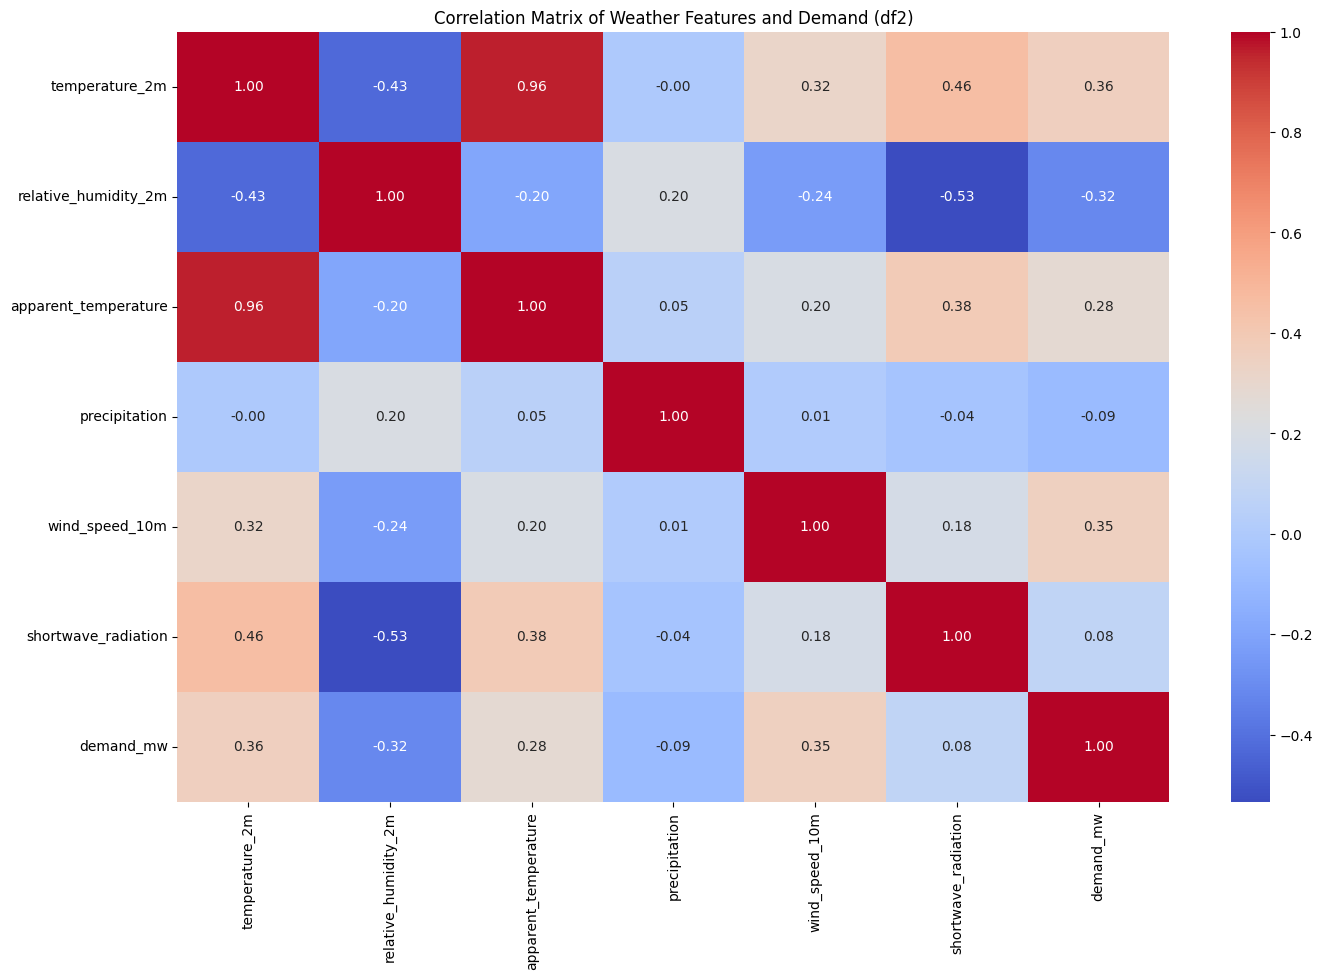

In [13]:
plt.figure(figsize=(16, 10))
weather_cols = ['temperature_2m', 'relative_humidity_2m', 'apparent_temperature', 'precipitation', 'wind_speed_10m', 'shortwave_radiation', 'demand_mw']
corr_matrix = df2[weather_cols].corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Matrix of Weather Features and Demand (df2)')
plt.show()

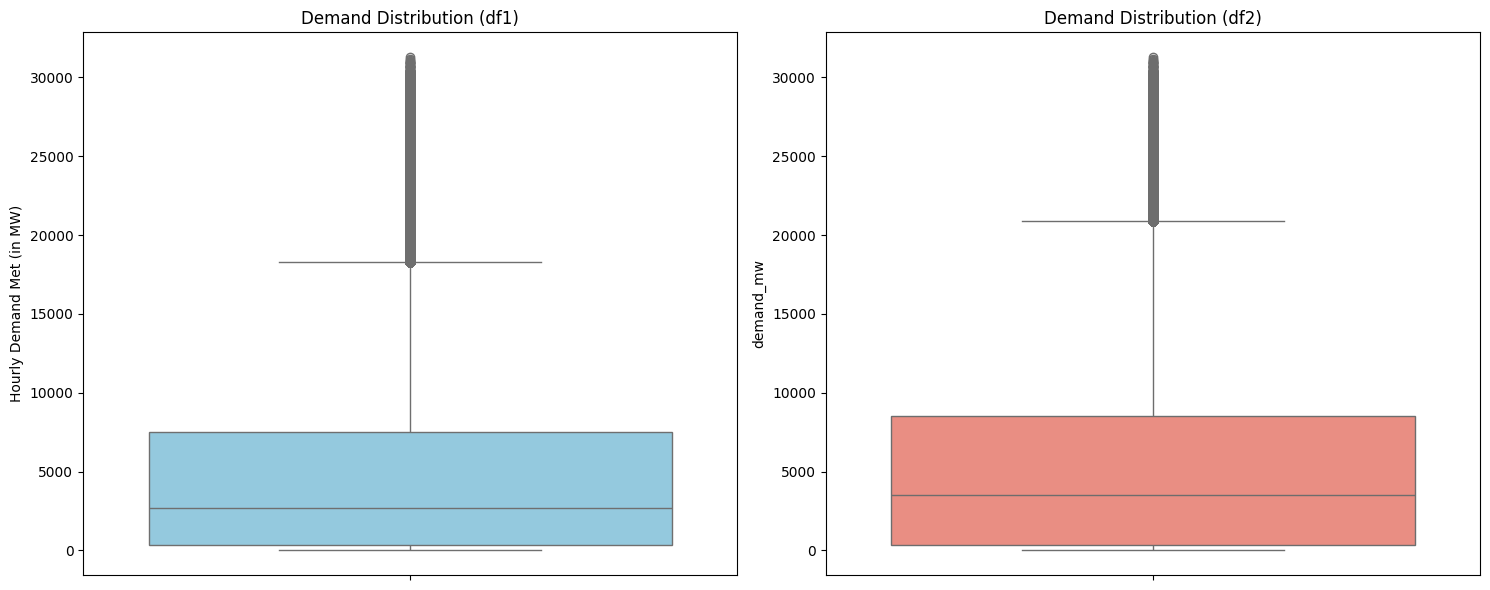

In [14]:
fig, axes = plt.subplot_mosaic([['df1', 'df2']], figsize=(15, 6))

sns.boxplot(y=df1['Hourly Demand Met (in MW)'], ax=axes['df1'], color='skyblue')
axes['df1'].set_title('Demand Distribution (df1)')

sns.boxplot(y=df2['demand_mw'], ax=axes['df2'], color='salmon')
axes['df2'].set_title('Demand Distribution (df2)')

plt.tight_layout()
plt.show()

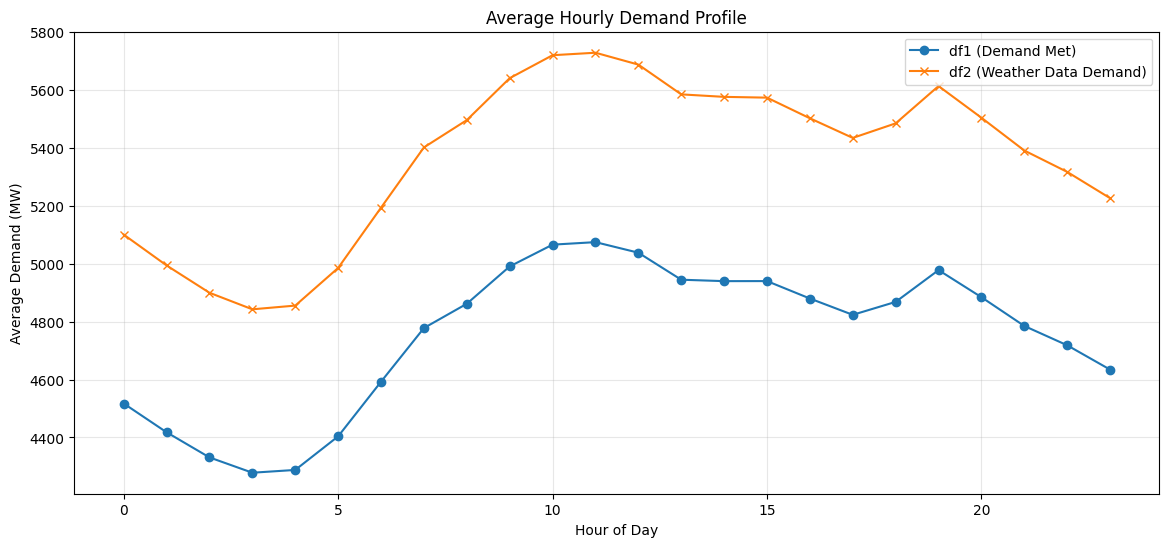

In [15]:
plt.figure(figsize=(14, 6))

hourly_avg_df1 = df1.groupby('Hour')['Hourly Demand Met (in MW)'].mean()
hourly_avg_df2 = df2.groupby('hour')['demand_mw'].mean()

plt.plot(hourly_avg_df1.index, hourly_avg_df1.values, label='df1 (Demand Met)', marker='o')
plt.plot(hourly_avg_df2.index, hourly_avg_df2.values, label='df2 (Weather Data Demand)', marker='x')

plt.xlabel('Hour of Day')
plt.ylabel('Average Demand (MW)')
plt.title('Average Hourly Demand Profile')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

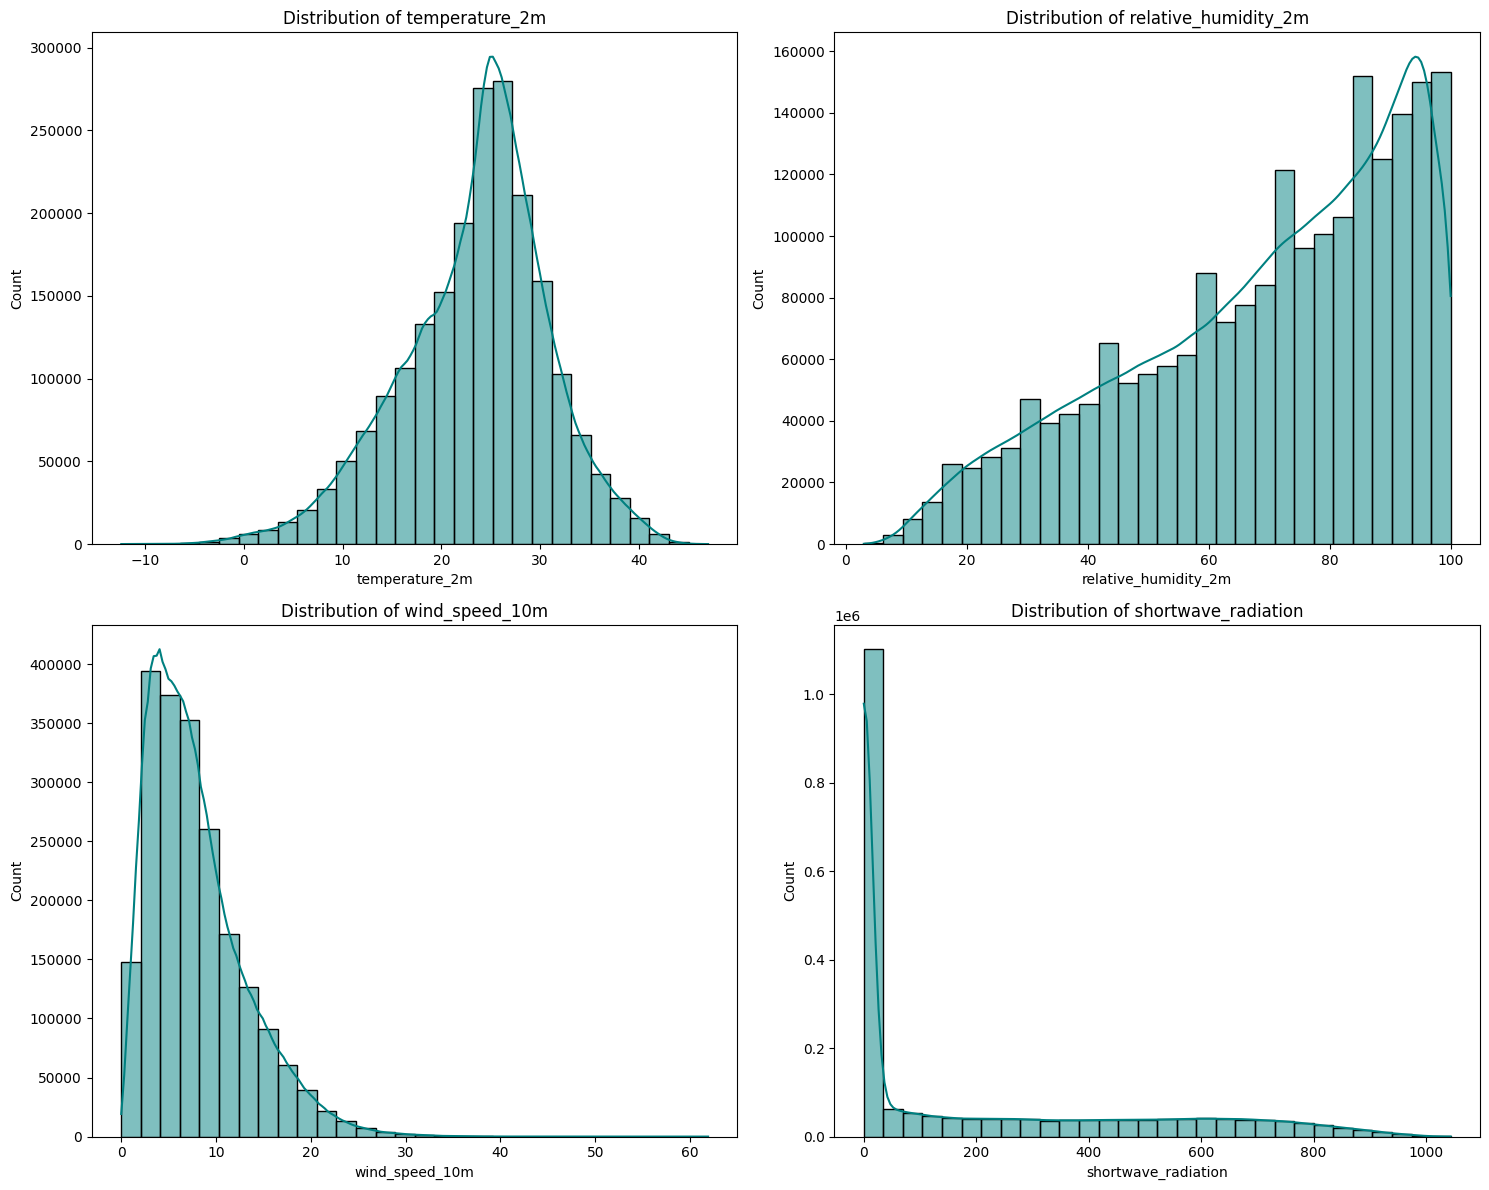

In [16]:
weather_vars = ['temperature_2m', 'relative_humidity_2m', 'wind_speed_10m', 'shortwave_radiation']

fig, axes = plt.subplots(2, 2, figsize=(15, 12))
axes = axes.flatten()

for i, var in enumerate(weather_vars):
    sns.histplot(df2[var], bins=30, kde=True, ax=axes[i], color='teal')
    axes[i].set_title(f'Distribution of {var}')

plt.tight_layout()
plt.show()

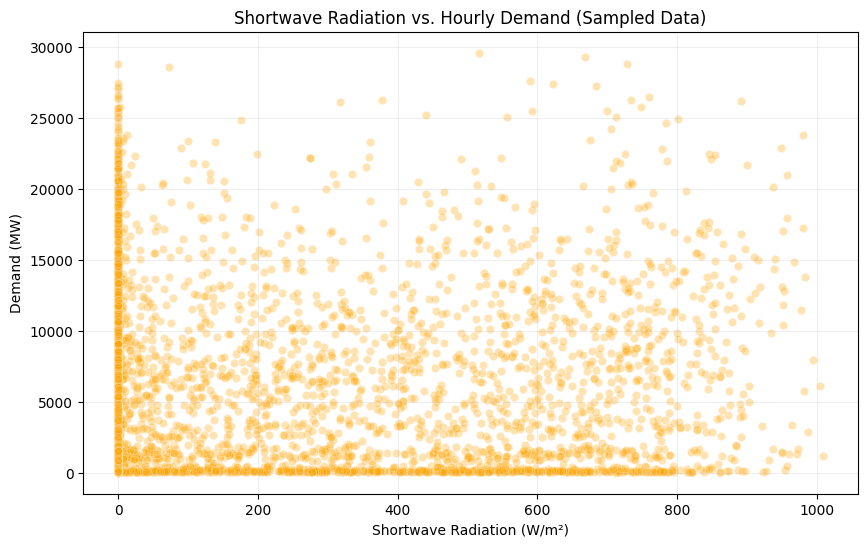

In [17]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df2.sample(5000), x='shortwave_radiation', y='demand_mw', alpha=0.3, color='orange')
plt.title('Shortwave Radiation vs. Hourly Demand (Sampled Data)')
plt.xlabel('Shortwave Radiation (W/m²)')
plt.ylabel('Demand (MW)')
plt.grid(True, alpha=0.2)
plt.show()

C:\Users\gutim\AppData\Local\Temp\ipykernel_28348\3932160379.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='year', y='demand_mw', data=df2, palette='Set2')


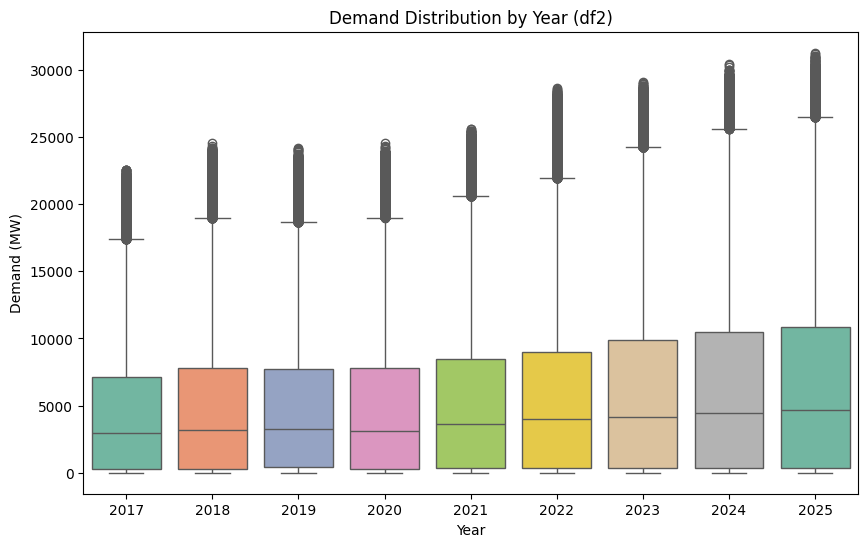

In [18]:
plt.figure(figsize=(10, 6))
sns.boxplot(x='year', y='demand_mw', data=df2, palette='Set2')
plt.title('Demand Distribution by Year (df2)')
plt.xlabel('Year')
plt.ylabel('Demand (MW)')
plt.show()

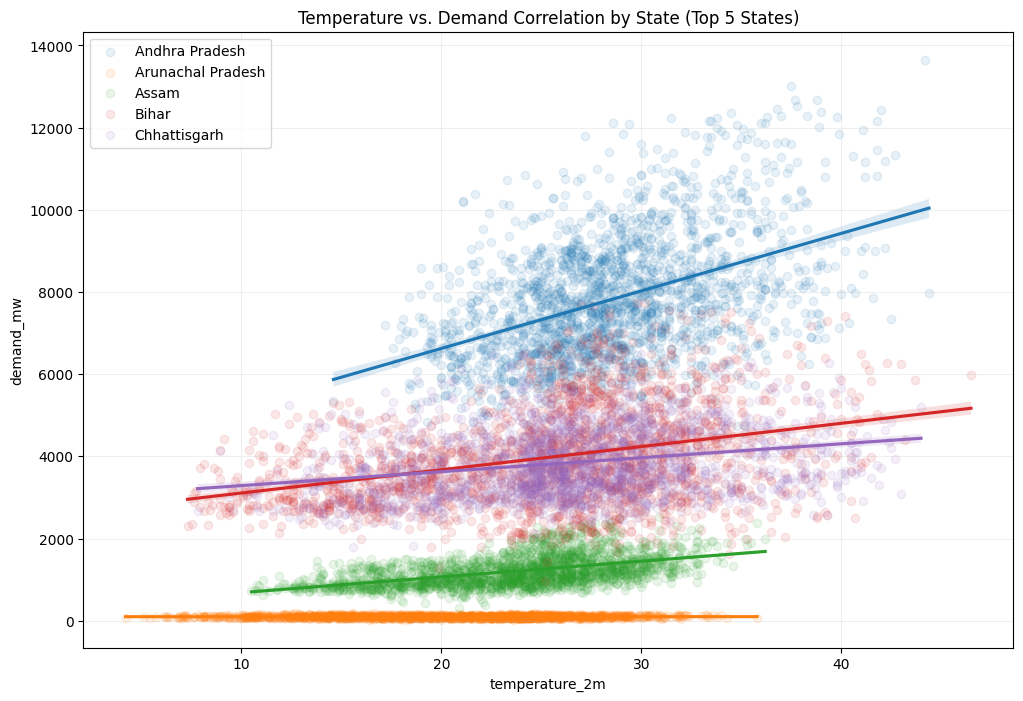

In [19]:
top_states = df2['state'].value_counts().nlargest(5).index
state_subset = df2[df2['state'].isin(top_states)]

plt.figure(figsize=(12, 8))
for state in top_states:
    subset = state_subset[state_subset['state'] == state]
    # Sampling for performance if dataset is large
    if len(subset) > 2000:
        subset = subset.sample(2000)
    sns.regplot(data=subset, x='temperature_2m', y='demand_mw', scatter_kws={'alpha':0.1}, label=state)

plt.title('Temperature vs. Demand Correlation')
plt.legend()
plt.grid(True, alpha=0.2)
plt.show()

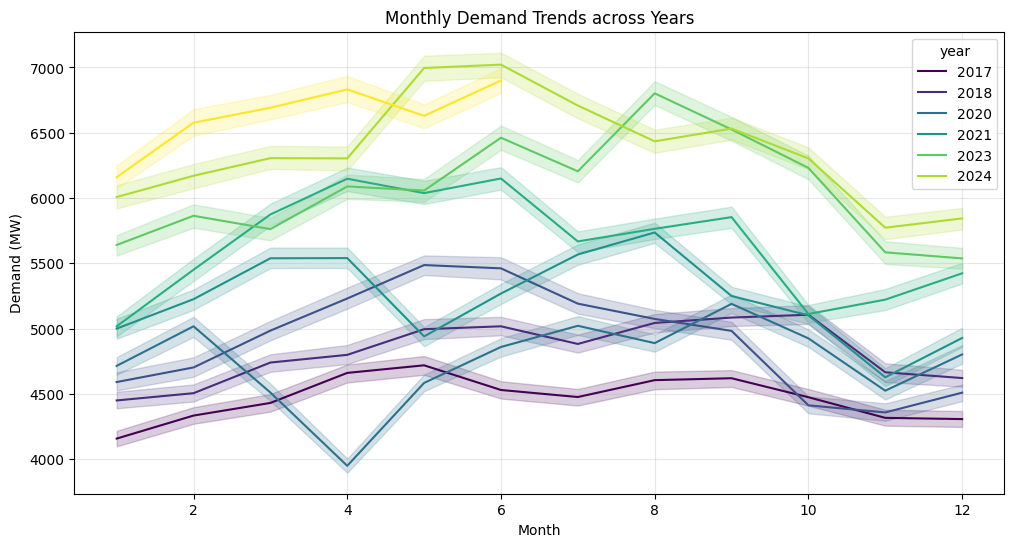

In [20]:
df2['month'] = df2['date'].dt.month
plt.figure(figsize=(12, 6))
sns.lineplot(data=df2, x='month', y='demand_mw', hue='year', palette='viridis')
plt.title('Monthly Demand Trends across Years')
plt.xlabel('Month')
plt.ylabel('Demand (MW)')
plt.grid(True, alpha=0.3)
plt.show()

In [21]:
from lightgbm import LGBMRegressor
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.metrics import mean_absolute_percentage_error, mean_absolute_error, mean_squared_error

features = ['state_encoded', 'hour', 'month', 'year', 'temperature_2m', 'relative_humidity_2m', 'apparent_temperature', 'precipitation', 'wind_speed_10m', 'shortwave_radiation']
target = 'demand_mw'

df_model = df2.sort_values(['date', 'hour'])

X = df_model[features]
y = df_model[target]

split_idx = int(len(df_model) * 0.8)
X_train, X_test = X.iloc[:split_idx], X.iloc[split_idx:]
y_train, y_test = y.iloc[:split_idx], y.iloc[split_idx:]

print(f'Training set size: {len(X_train)}')
print(f'Test set size: {len(X_test)}')

Training set size: 1654156
Test set size: 413539


In [22]:
from pandas.api.types import is_numeric_dtype
import warnings
warnings.filterwarnings('ignore')

def reduce_mem_usage(df):
    for col in df.columns:
        if is_numeric_dtype(df[col]):
            col_type = df[col].dtype
            if 'bool' in str(col_type): continue
            c_min, c_max = df[col].min(), df[col].max()
            if 'int' in str(col_type):
                if c_min > np.iinfo(np.int8).min and c_max < np.iinfo(np.int8).max: df[col] = df[col].astype(np.int8)
                elif c_min > np.iinfo(np.int16).min and c_max < np.iinfo(np.int16).max: df[col] = df[col].astype(np.int16)
                elif c_min > np.iinfo(np.int32).min and c_max < np.iinfo(np.int32).max: df[col] = df[col].astype(np.int32)
            elif 'float' in str(col_type):
                df[col] = df[col].astype(np.float32)
    return df

def integrate_and_clean_datasets(df_demand, df_weather):
    print("[INFO] Merging datasets...")
    d1 = df_demand.copy()
    d1.rename(columns={'State': 'state', 'Date': 'date', 'Hour': 'hour', 'Hourly Demand Met (in MW)': 'demand_mw'}, inplace=True)
    d1['date'] = pd.to_datetime(d1['date'])
    
    d2 = df_weather.copy()
    d2['date'] = pd.to_datetime(d2['date'])
    if 'demand_mw' in d2.columns: d2.drop(columns=['demand_mw'], inplace=True)
        
    df_merged = pd.merge(d1, d2, on=['state', 'date', 'hour'], how='inner')
    df_merged.dropna(subset=['demand_mw', 'temperature_2m'], inplace=True)
    
    print("[INFO] Clipping extreme outliers to reduce Max Error...")
    def clip_outliers(group):
        lower = group.quantile(0.005)
        upper = group.quantile(0.995)
        return group.clip(lower, upper)
    
    df_merged['demand_mw'] = df_merged.groupby('state')['demand_mw'].transform(clip_outliers)
    
    df_merged = reduce_mem_usage(df_merged)
    print(f"[SUCCESS] new dataset shape: {df_merged.shape}")
    return df_merged

df_master = integrate_and_clean_datasets(df1, df2)

[INFO] Standardizing and merging datasets...
[INFO] Clipping extreme outliers to reduce Max Error...
[SUCCESS] Merged & Cleaned dataset shape: (2067695, 31)


In [23]:
import holidays

class StrictFeatureEngineer:
    def __init__(self, df):
        self.df = df.copy()
        self.df.sort_values(by=['state', 'date', 'hour'], inplace=True)
        
    def add_temporal_features(self):
        print("[INFO] adding features...")
        self.df['dayofweek'] = self.df['date'].dt.dayofweek
        self.df['month'] = self.df['date'].dt.month
        self.df['is_weekend'] = (self.df['dayofweek'] >= 5).astype(np.int8)
        
        self.df['hour_sin'] = np.sin(2 * np.pi * self.df['hour'] / 23.0).astype(np.float32)
        self.df['hour_cos'] = np.cos(2 * np.pi * self.df['hour'] / 23.0).astype(np.float32)
        self.df['month_sin'] = np.sin(2 * np.pi * self.df['month'] / 12.0).astype(np.float32)
        self.df['month_cos'] = np.cos(2 * np.pi * self.df['month'] / 12.0).astype(np.float32)
        return self

    def add_holidays(self):
        print("[INFO] mapping holidays...")
        years = range(self.df['date'].dt.year.min(), self.df['date'].dt.year.max() + 1)
        in_holidays = holidays.India(years=years)
        self.df['is_holiday'] = self.df['date'].dt.date.apply(lambda x: 1 if x in in_holidays else 0).astype(np.int8)
        return self

    def add_strict_lags_and_rolling(self):
        print("[INFO] calculating...")
        grouped = self.df.groupby('state')['demand_mw']
        
        for lag in [24, 48, 168]:
            self.df[f'lag_{lag}h'] = grouped.shift(lag).astype(np.float32)
            
        for w in [24, 168]:
            self.df[f'rolling_mean_{w}h'] = grouped.transform(lambda x: x.shift(24).rolling(w).mean()).astype(np.float32)
            self.df[f'rolling_std_{w}h'] = grouped.transform(lambda x: x.shift(24).rolling(w).std()).astype(np.float32)
        return self

    def add_weather_interactions(self):
        print("[INFO] building weather interaction features...")
        if 'temperature_2m' in self.df.columns and 'relative_humidity_2m' in self.df.columns:
            self.df['temp_humidity_idx'] = (self.df['temperature_2m'] * self.df['relative_humidity_2m']).astype(np.float32)
            self.df['CDH'] = np.maximum(self.df['temperature_2m'] - 18, 0).astype(np.float32)
            self.df['HDH'] = np.maximum(18 - self.df['temperature_2m'], 0).astype(np.float32)
        return self

    def build(self):
        self.add_temporal_features().add_holidays().add_strict_lags_and_rolling().add_weather_interactions()
        self.df.dropna(inplace=True)
        
        self.states = sorted(self.df['state'].unique())
        self.state_to_idx = {state: idx for idx, state in enumerate(self.states)}
        self.df['state_encoded'] = self.df['state'].map(self.state_to_idx)
        
        print(f"[SUCCESS] feature engineering complete. Final shape: {self.df.shape}")
        return self.df, self.state_to_idx

engineer = StrictFeatureEngineer(df_master)
df_features, state_mapping = engineer.build()

[INFO] Adding temporal and cyclical features...
[INFO] Mapping Indian holidays...
[INFO] Calculating STRICT 24h-shifted lags and rolling averages (Zero Leakage)...
[INFO] Building weather interaction features...
[SUCCESS] Feature engineering complete. Final shape: (2062347, 48)


In [24]:
import optuna
import lightgbm as lgb
from sklearn.metrics import mean_absolute_error

print("======================================================")
print("STRICT TEMPORAL SPLIT & HYPERPARAMETER TUNING")
print("======================================================")

train_mask = df_features['date'].dt.year < 2024
val_mask = df_features['date'].dt.year == 2024
test_mask = df_features['date'].dt.year >= 2025

exclude_cols = ['date', 'demand_mw', 'state']
features = [c for c in df_features.columns if c not in exclude_cols]

X_train = df_features.loc[train_mask, features]
y_train = np.log1p(df_features.loc[train_mask, 'demand_mw'])

X_val = df_features.loc[val_mask, features]
y_val = np.log1p(df_features.loc[val_mask, 'demand_mw'])

X_test = df_features.loc[test_mask, features]
y_test = np.log1p(df_features.loc[test_mask, 'demand_mw'])

print(f"[INFO] Train: {len(X_train)} | Val: {len(X_val)} | Test: {len(X_test)}")

def objective(trial):
    params = {
        'objective': 'huber',
        'metric': 'mae',
        'n_estimators': trial.suggest_int('n_estimators', 800, 2000),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.05, log=True),
        'num_leaves': trial.suggest_int('num_leaves', 63, 255),
        'max_depth': trial.suggest_int('max_depth', 6, 12),
        'min_child_samples': trial.suggest_int('min_child_samples', 50, 200),
        'subsample': trial.suggest_float('subsample', 0.7, 0.9),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.7, 0.9),
        'reg_alpha': trial.suggest_float('reg_alpha', 0.1, 10.0, log=True),
        'reg_lambda': trial.suggest_float('reg_lambda', 0.1, 10.0, log=True),
        'n_jobs': -1,
        'random_state': 42,
        'verbose': -1
    }
    
    model = lgb.LGBMRegressor(**params)
    model.fit(
        X_train, y_train, 
        eval_set=[(X_val, y_val)], 
        callbacks=[lgb.early_stopping(50, verbose=False)]
    )
    
    preds = np.expm1(model.predict(X_val))
    true_vals = np.expm1(y_val)
    return mean_absolute_error(true_vals, preds)

def optuna_callback(study, trial):
    print(f"trial {trial.number} finished | Val MAE: {trial.value:.2f} MW | Best MAE: {study.best_value:.2f} MW")

print("\n[INFO] now onto hyperparameters...")
study = optuna.create_study(direction='minimize')
study.optimize(objective, n_trials=15, callbacks=[optuna_callback]) 

best_params = study.best_params
print(f"\n[SUCCESS] Best Parameters Found: {best_params}")

⚙️ STRICT TEMPORAL SPLIT & HYPERPARAMETER TUNING


[I 2026-04-26 17:11:11,058] A new study created in memory with name: no-name-9e8e33cd-35b0-49f1-b9cd-089b6903a0d1


[INFO] Train: 1694763 | Val: 245952 | Test: 121632

[INFO] Starting Hyperparameter Optimization...


[I 2026-04-26 17:11:58,223] Trial 0 finished with value: 263.165358648659 and parameters: {'n_estimators': 1120, 'learning_rate': 0.036711670422717106, 'num_leaves': 241, 'max_depth': 10, 'min_child_samples': 58, 'subsample': 0.701820746120131, 'colsample_bytree': 0.8694220451926065, 'reg_alpha': 8.090828601216383, 'reg_lambda': 7.783137974320205}. Best is trial 0 with value: 263.165358648659.


Trial 0 finished | Val MAE: 263.17 MW | Best MAE: 263.17 MW


[I 2026-04-26 17:12:24,689] Trial 1 finished with value: 265.5063993125905 and parameters: {'n_estimators': 1683, 'learning_rate': 0.049435998521908844, 'num_leaves': 72, 'max_depth': 10, 'min_child_samples': 180, 'subsample': 0.8230744826474481, 'colsample_bytree': 0.7742922271799133, 'reg_alpha': 2.3492790639435968, 'reg_lambda': 0.8861207062275237}. Best is trial 0 with value: 263.165358648659.


... (23 outputs left out)

[I 2026-04-26 17:23:07,489] Trial 13 finished with value: 261.30813905184834 and parameters: {'n_estimators': 1035, 'learning_rate': 0.0181538303668562, 'num_leaves': 253, 'max_depth': 12, 'min_child_samples': 133, 'subsample': 0.7266671962446286, 'colsample_bytree': 0.8501662777746698, 'reg_alpha': 1.127381293532398, 'reg_lambda': 9.472830265093895}. Best is trial 13 with value: 261.30813905184834.


Trial 13 finished | Val MAE: 261.31 MW | Best MAE: 261.31 MW


[I 2026-04-26 17:24:45,432] Trial 14 finished with value: 261.3087263821088 and parameters: {'n_estimators': 1116, 'learning_rate': 0.016961136818956394, 'num_leaves': 252, 'max_depth': 11, 'min_child_samples': 132, 'subsample': 0.7173042593715419, 'colsample_bytree': 0.8203952844284729, 'reg_alpha': 1.4322377061260587, 'reg_lambda': 2.6559760174243108}. Best is trial 13 with value: 261.30813905184834.


Trial 14 finished | Val MAE: 261.31 MW | Best MAE: 261.31 MW

[SUCCESS] Best Parameters Found: {'n_estimators': 1035, 'learning_rate': 0.0181538303668562, 'num_leaves': 253, 'max_depth': 12, 'min_child_samples': 133, 'subsample': 0.7266671962446286, 'colsample_bytree': 0.8501662777746698, 'reg_alpha': 1.127381293532398, 'reg_lambda': 9.472830265093895}


In [25]:
import joblib
import os

quantiles = [0.1, 0.5, 0.9]
models = {}
raw_preds = {}

print("\n======================================================")
print("TRAINING FINAL MODELS & EXPORTING TO ../models/")
print("======================================================")

os.makedirs('../models', exist_ok=True)

X_train_full = pd.concat([X_train, X_val])
y_train_full = pd.concat([y_train, y_val])

for alpha in quantiles:
    print(f"\n---> Training Quantile P{int(alpha*100)} Model <---")
    q_params = best_params.copy()
    
    if alpha != 0.5:
        q_params['min_child_samples'] = int(q_params['min_child_samples'] * 1.5)
        q_params['max_depth'] = max(4, q_params['max_depth'] - 2)
        
    q_params.update({'objective': 'quantile', 'alpha': alpha, 'verbose': -1})
    
    model = lgb.LGBMRegressor(**q_params)
    
    callbacks = [
        lgb.early_stopping(stopping_rounds=100, verbose=True),
        lgb.log_evaluation(period=200)
    ]
    
    model.fit(
        X_train_full, y_train_full, 
        eval_set=[(X_train_full, y_train_full), (X_test, y_test)], 
        callbacks=callbacks
    )
    
    models[f'P{int(alpha*100)}'] = model
    raw_preds[f'P{int(alpha*100)}'] = np.expm1(model.predict(X_test))
    
    model_path = f'../models/prometheus_lgbm_P{int(alpha*100)}.pkl'
    joblib.dump(model, model_path)
    print("[SUCCESS] model saved")

joblib.dump(state_mapping, '../models/state_mapping.pkl')

print("\n[INFO] applying monotonic sorting...")
sorted_preds = np.sort([raw_preds['P10'], raw_preds['P50'], raw_preds['P90']], axis=0)
preds = {
    'P10': sorted_preds[0],
    'P50': sorted_preds[1],
    'P90': sorted_preds[2]
}

y_true = np.expm1(y_test)
print("[SUCCESS] final models ready")


🚀 TRAINING FINAL MODELS & EXPORTING TO ../models/

---> Training Quantile P10 Model <---
Training until validation scores don't improve for 100 rounds
[200]	training's quantile: 0.0650429	valid_1's quantile: 0.0781987
[400]	training's quantile: 0.0191565	valid_1's quantile: 0.0243304
[600]	training's quantile: 0.0146831	valid_1's quantile: 0.0176842
[800]	training's quantile: 0.0140959	valid_1's quantile: 0.0168907
Early stopping, best iteration is:
[848]	training's quantile: 0.0139983	valid_1's quantile: 0.0168769
[SUCCESS] Saved model to ../models/prometheus_lgbm_P10.pkl

---> Training Quantile P50 Model <---
Training until validation scores don't improve for 100 rounds
[200]	training's quantile: 0.0411286	valid_1's quantile: 0.0438496
[400]	training's quantile: 0.0272866	valid_1's quantile: 0.0285659
[600]	training's quantile: 0.0262929	valid_1's quantile: 0.0278038
[800]	training's quantile: 0.0257112	valid_1's quantile: 0.0275437
[1000]	training's quantile: 0.0252518	valid_1's qu


[INFO] Running Context-Aware Isolation Forest for Anomaly Metrics...

🏆 COMPREHENSIVE MODEL EVALUATION METRICS 🏆


,Value
MAE (MW),259.1318
RMSE (MW),550.0897
Median AE (MW),84.9784
Max Error (MW),"14,511.1788"
Safe MAPE (%),5.7441
WAPE (%),3.9168
R-Squared (R2),0.9938
Pinball Loss (P10),75.3632
Pinball Loss (P90),55.1594
Coverage Rate (P10-P90) (%),77.6473



[INFO] Calculating SHAP values for model explainability...


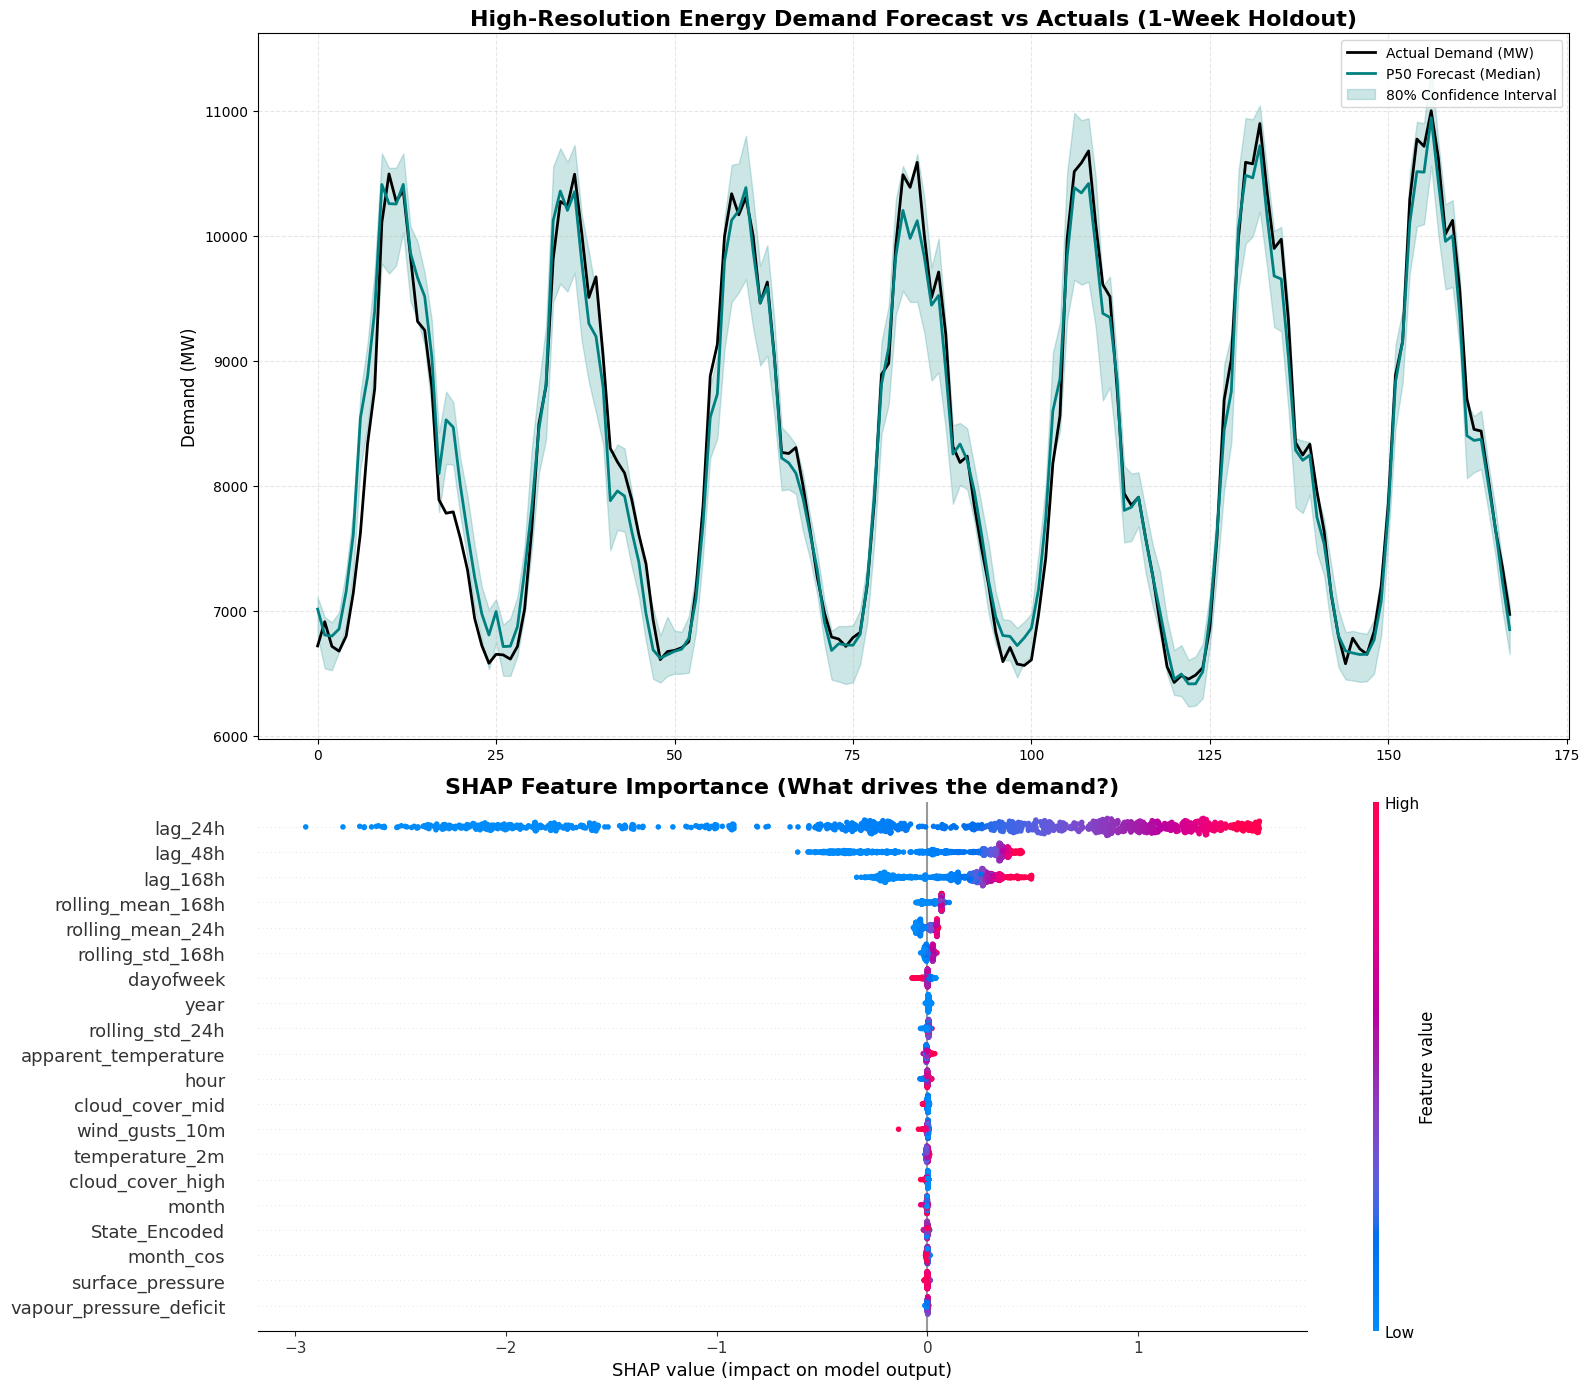

In [26]:
import shap
from sklearn.ensemble import IsolationForest
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score, 
    median_absolute_error, max_error,
    accuracy_score, precision_score, recall_score, f1_score
)

def safe_mape(y_true_arr, y_pred_arr):
    mask = y_true_arr > 0.1 
    if np.sum(mask) == 0: return 0.0
    return np.mean(np.abs((y_true_arr[mask] - y_pred_arr[mask]) / y_true_arr[mask])) * 100

def evaluate_forecasting_and_anomalies(y_true, preds_dict):
    y_true_arr = np.array(y_true, dtype=np.float64)
    y_pred = np.array(preds_dict['P50'], dtype=np.float64)
    y_p10 = np.array(preds_dict['P10'], dtype=np.float64)
    y_p90 = np.array(preds_dict['P90'], dtype=np.float64)
    
    metrics = {}
    
    metrics['MAE (MW)'] = mean_absolute_error(y_true_arr, y_pred)
    metrics['RMSE (MW)'] = np.sqrt(mean_squared_error(y_true_arr, y_pred))
    metrics['Median AE (MW)'] = median_absolute_error(y_true_arr, y_pred)
    metrics['Max Error (MW)'] = max_error(y_true_arr, y_pred)
    metrics['Safe MAPE (%)'] = safe_mape(y_true_arr, y_pred)
    metrics['WAPE (%)'] = (np.sum(np.abs(y_true_arr - y_pred)) / np.sum(y_true_arr)) * 100
    metrics['R-Squared (R2)'] = r2_score(y_true_arr, y_pred)
    
    def pinball_loss(y, q_pred, alpha):
        diff = y - q_pred
        return np.mean(np.maximum(alpha * diff, (alpha - 1) * diff))
    
    metrics['Pinball Loss (P10)'] = pinball_loss(y_true_arr, y_p10, 0.1)
    metrics['Pinball Loss (P90)'] = pinball_loss(y_true_arr, y_p90, 0.9)
    metrics['Coverage Rate (P10-P90) (%)'] = np.mean((y_true_arr >= y_p10) & (y_true_arr <= y_p90)) * 100

    print("\n[INFO] running isolation forest...")
    np.random.seed(42)
    
    anomaly_mask = np.random.rand(len(y_true_arr)) < 0.05
    y_synthetic = y_true_arr.copy()
    y_synthetic[anomaly_mask] = y_synthetic[anomaly_mask] * np.random.uniform(0.60, 0.75, size=anomaly_mask.sum())
    
    pct_error = (y_pred - y_synthetic) / y_pred
    
    pct_error_series = pd.Series(pct_error)
    rolling_mean = pct_error_series.rolling(window=24, min_periods=1).mean()
    rolling_std = pct_error_series.rolling(window=24, min_periods=1).std().fillna(1e-5)
    z_scores = ((pct_error_series - rolling_mean) / (rolling_std + 1e-5)).values
    
    features_for_if = np.column_stack([pct_error, z_scores])
    iso_forest = IsolationForest(contamination=0.05, random_state=42, n_estimators=300)
    iso_preds = iso_forest.fit_predict(features_for_if)
    
    pred_anomalies = np.where((iso_preds == -1) & (z_scores > 2.0), 1, 0)
    true_anomalies = np.where(anomaly_mask, 1, 0)
    
    metrics['Anomaly Accuracy (%)'] = accuracy_score(true_anomalies, pred_anomalies) * 100
    metrics['Anomaly Precision (%)'] = precision_score(true_anomalies, pred_anomalies) * 100
    metrics['Anomaly Recall (%)'] = recall_score(true_anomalies, pred_anomalies) * 100
    metrics['Anomaly F1 Score (%)'] = f1_score(true_anomalies, pred_anomalies) * 100
    
    return pd.DataFrame.from_dict(metrics, orient='index', columns=['Value'])

metrics_df = evaluate_forecasting_and_anomalies(y_true, preds)
metrics_df['Value'] = metrics_df['Value'].apply(lambda x: f"{x:,.4f}")

print("\n======================================================")
print("COMPREHENSIVE MODEL EVALUATION METRICS")
print("======================================================")
display(metrics_df)

fig, axes = plt.subplots(2, 1, figsize=(16, 14), gridspec_kw={'height_ratios': [2, 1.5]})

plot_slice = 168
idx = np.arange(plot_slice)

y_true_plot = np.array(y_true)[:plot_slice]
axes[0].plot(idx, y_true_plot, label='Actual Demand (MW)', color='black', linewidth=2)
axes[0].plot(idx, preds['P50'][:plot_slice], label='P50 Forecast (Median)', color='teal', linewidth=2)
axes[0].fill_between(idx, preds['P10'][:plot_slice], preds['P90'][:plot_slice], color='teal', alpha=0.2, label='80% Confidence Interval')
axes[0].set_title('High-Resolution Energy Demand Forecast vs Actuals (1-Week Holdout)', fontsize=16, fontweight='bold')
axes[0].set_ylabel('Demand (MW)', fontsize=12)
axes[0].legend(loc='upper right')
axes[0].grid(True, alpha=0.3, linestyle='--')

print("\n[INFO] Calculating SHAP values for model explainability...")
explainer = shap.TreeExplainer(models['P50'])
sample_X = X_test.sample(1000, random_state=42) 
shap_values = explainer.shap_values(sample_X)

plt.sca(axes[1])
shap.summary_plot(shap_values, sample_X, show=False, plot_size=None)
axes[1].set_title('SHAP Feature Importance (What drives the demand?)', fontsize=16, fontweight='bold')

plt.tight_layout()
plt.show()

In [27]:
warnings.filterwarnings('ignore')

print("======================================================")
print("ADVANCED CALENDAR FEATURE ENGINEERING & SPLIT")
print("======================================================")

states = sorted(df_master['state'].unique())
state_to_idx = {state: idx for idx, state in enumerate(states)}

df_plan = df_master[['state', 'date', 'hour', 'demand_mw']].copy()
df_plan['state_encoded'] = df_plan['state'].map(state_to_idx)

df_plan['year'] = df_plan['date'].dt.year
df_plan['month'] = df_plan['date'].dt.month
df_plan['day'] = df_plan['date'].dt.day
df_plan['dayofweek'] = df_plan['date'].dt.dayofweek
df_plan['dayofyear'] = df_plan['date'].dt.dayofyear
df_plan['weekofyear'] = df_plan['date'].dt.isocalendar().week.astype(int)
df_plan['quarter'] = df_plan['date'].dt.quarter
df_plan['is_weekend'] = (df_plan['dayofweek'] >= 5).astype(int)

df_plan['is_peak'] = df_plan['hour'].isin([18, 19, 20, 21, 22]).astype(int)
df_plan['is_solar'] = df_plan['hour'].isin([10, 11, 12, 13, 14, 15, 16, 17]).astype(int)

df_plan['hour_sin'] = np.sin(2 * np.pi * df_plan['hour'] / 23.0)
df_plan['hour_cos'] = np.cos(2 * np.pi * df_plan['hour'] / 23.0)
df_plan['month_sin'] = np.sin(2 * np.pi * df_plan['month'] / 12.0)
df_plan['month_cos'] = np.cos(2 * np.pi * df_plan['month'] / 12.0)
df_plan['dayofweek_sin'] = np.sin(2 * np.pi * df_plan['dayofweek'] / 6.0)
df_plan['dayofweek_cos'] = np.cos(2 * np.pi * df_plan['dayofweek'] / 6.0)
df_plan['dayofyear_sin'] = np.sin(2 * np.pi * df_plan['dayofyear'] / 365.25)
df_plan['dayofyear_cos'] = np.cos(2 * np.pi * df_plan['dayofyear'] / 365.25)

years = range(df_plan['year'].min(), df_plan['year'].max() + 2)
in_holidays = holidays.India(years=years)
df_plan['is_holiday'] = df_plan['date'].dt.date.apply(lambda x: 1 if x in in_holidays else 0)

plan_features = [
    'state_encoded', 'year', 'month', 'day', 'hour', 'dayofweek', 'dayofyear', 
    'weekofyear', 'quarter', 'is_weekend', 'is_holiday', 'is_peak', 'is_solar',
    'hour_sin', 'hour_cos', 'month_sin', 'month_cos', 
    'dayofweek_sin', 'dayofweek_cos', 'dayofyear_sin', 'dayofyear_cos'
]

categorical_features = ['state_encoded', 'month', 'dayofweek', 'hour', 'quarter', 'is_weekend', 'is_holiday', 'is_peak', 'is_solar']

train_mask = df_plan['year'] < 2024
val_mask = df_plan['year'] == 2024
test_mask = df_plan['year'] >= 2025

X_train_p = df_plan.loc[train_mask, plan_features]
y_train_p = np.log1p(df_plan.loc[train_mask, 'demand_mw']) # LOG1P IS BACK

X_val_p = df_plan.loc[val_mask, plan_features]
y_val_p = np.log1p(df_plan.loc[val_mask, 'demand_mw'])

X_test_p = df_plan.loc[test_mask, plan_features]
y_test_p = np.log1p(df_plan.loc[test_mask, 'demand_mw'])

print(f"[INFO] Train Size (<2024): {len(X_train_p)} | Val Size (2024): {len(X_val_p)} | Test Size (>=2025): {len(X_test_p)}")

📅 1. ADVANCED CALENDAR FEATURE ENGINEERING & SPLIT
[INFO] Train Size (<2024): 1700111 | Val Size (2024): 245952 | Test Size (>=2025): 121632


In [28]:
print("======================================================")
print("OPTIMIZING HYPERPARAMETERS FOR MAPE & PEAKS")
print("======================================================")

def safe_mape(y_true_arr, y_pred_arr):
    mask = y_true_arr > 0.1 
    if np.sum(mask) == 0: return 0.0
    return np.mean(np.abs((y_true_arr[mask] - y_pred_arr[mask]) / y_true_arr[mask])) * 100

def objective_planner(trial):
    params = {
        'objective': 'regression_l1',
        'metric': 'mae',
        'n_estimators': trial.suggest_int('n_estimators', 1500, 4000),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.1, log=True),
        'num_leaves': trial.suggest_int('num_leaves', 255, 1024),
        'max_depth': trial.suggest_int('max_depth', 10, 25),
        'min_child_samples': trial.suggest_int('min_child_samples', 10, 100),
        'subsample': trial.suggest_float('subsample', 0.7, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.7, 1.0),
        'cat_smooth': trial.suggest_float('cat_smooth', 1.0, 50.0),
        'n_jobs': -1,
        'random_state': 42,
        'verbose': -1
    }
    
    model = lgb.LGBMRegressor(**params)
    
    model.fit(
        X_train_p, y_train_p, 
        eval_set=[(X_val_p, y_val_p)], 
        categorical_feature=categorical_features, # NATIVE CATEGORICALS
        callbacks=[lgb.early_stopping(50, verbose=False)]
    )
    
    preds = np.expm1(model.predict(X_val_p))
    true_vals = np.expm1(y_val_p)
    
    return safe_mape(true_vals.values, preds)

def optuna_callback_planner(study, trial):
    print(f"Trial {trial.number} finished | Val MAPE: {trial.value:.2f}% | Best MAPE: {study.best_value:.2f}%")

study_planner = optuna.create_study(direction='minimize')
study_planner.optimize(objective_planner, n_trials=15, callbacks=[optuna_callback_planner]) 

best_planner_params = study_planner.best_params
print(f"\n[SUCCESS] Best Parameters Found: {best_planner_params}")

[I 2026-04-26 17:32:36,364] A new study created in memory with name: no-name-37913f40-4698-4d89-bce0-d74c3082411e


⚙️ 2. OPTIMIZING HYPERPARAMETERS FOR MAPE & PEAKS


[I 2026-04-26 17:33:30,068] Trial 0 finished with value: 11.766342924186715 and parameters: {'n_estimators': 2563, 'learning_rate': 0.051615759102578866, 'num_leaves': 963, 'max_depth': 22, 'min_child_samples': 47, 'subsample': 0.8512472558462172, 'colsample_bytree': 0.8159231488508802, 'cat_smooth': 29.817576513854714}. Best is trial 0 with value: 11.766342924186715.


Trial 0 finished | Val MAPE: 11.77% | Best MAPE: 11.77%


[I 2026-04-26 17:34:14,831] Trial 1 finished with value: 11.795622147273301 and parameters: {'n_estimators': 3005, 'learning_rate': 0.04589328052645735, 'num_leaves': 859, 'max_depth': 12, 'min_child_samples': 73, 'subsample': 0.7274113394736156, 'colsample_bytree': 0.8949720742534215, 'cat_smooth': 48.84410534330659}. Best is trial 0 with value: 11.766342924186715.


Trial 1 finished | Val MAPE: 11.80% | Best MAPE: 11.77%


... (22 outputs left out)

[I 2026-04-26 17:48:04,678] Trial 13 finished with value: 11.635881854633116 and parameters: {'n_estimators': 2059, 'learning_rate': 0.031164729585509185, 'num_leaves': 470, 'max_depth': 14, 'min_child_samples': 86, 'subsample': 0.9995806285204153, 'colsample_bytree': 0.7535522343837925, 'cat_smooth': 22.031669091750544}. Best is trial 11 with value: 11.475016463959484.


Trial 13 finished | Val MAPE: 11.64% | Best MAPE: 11.48%


[I 2026-04-26 17:49:16,292] Trial 14 finished with value: 11.525946500263387 and parameters: {'n_estimators': 1968, 'learning_rate': 0.01567004842297795, 'num_leaves': 375, 'max_depth': 10, 'min_child_samples': 82, 'subsample': 0.8979748040399401, 'colsample_bytree': 0.8090253612368226, 'cat_smooth': 11.48747773495154}. Best is trial 11 with value: 11.475016463959484.


Trial 14 finished | Val MAPE: 11.53% | Best MAPE: 11.48%

[SUCCESS] Best Parameters Found: {'n_estimators': 1545, 'learning_rate': 0.020847930488260204, 'num_leaves': 261, 'max_depth': 17, 'min_child_samples': 100, 'subsample': 0.734504453369282, 'colsample_bytree': 0.7027501587414166, 'cat_smooth': 17.633431525693762}


🚀 3. FINAL TRAINING, EXPORT & EVALUATION
[INFO] Training Final Planning Model...
Training until validation scores don't improve for 100 rounds
[200]	training's l1: 0.128809	valid_1's l1: 0.157371
[400]	training's l1: 0.0785933	valid_1's l1: 0.109354
[600]	training's l1: 0.0714682	valid_1's l1: 0.107095
Early stopping, best iteration is:
[610]	training's l1: 0.0712312	valid_1's l1: 0.107056

[SUCCESS] Model saved to: ../models/planner_model.pkl

--- PLANNING MODEL METRICS (2025 HOLDOUT) ---
MAE:  587.36 MW
RMSE: 1058.66 MW
MAPE: 10.75 %
R2:   0.9770


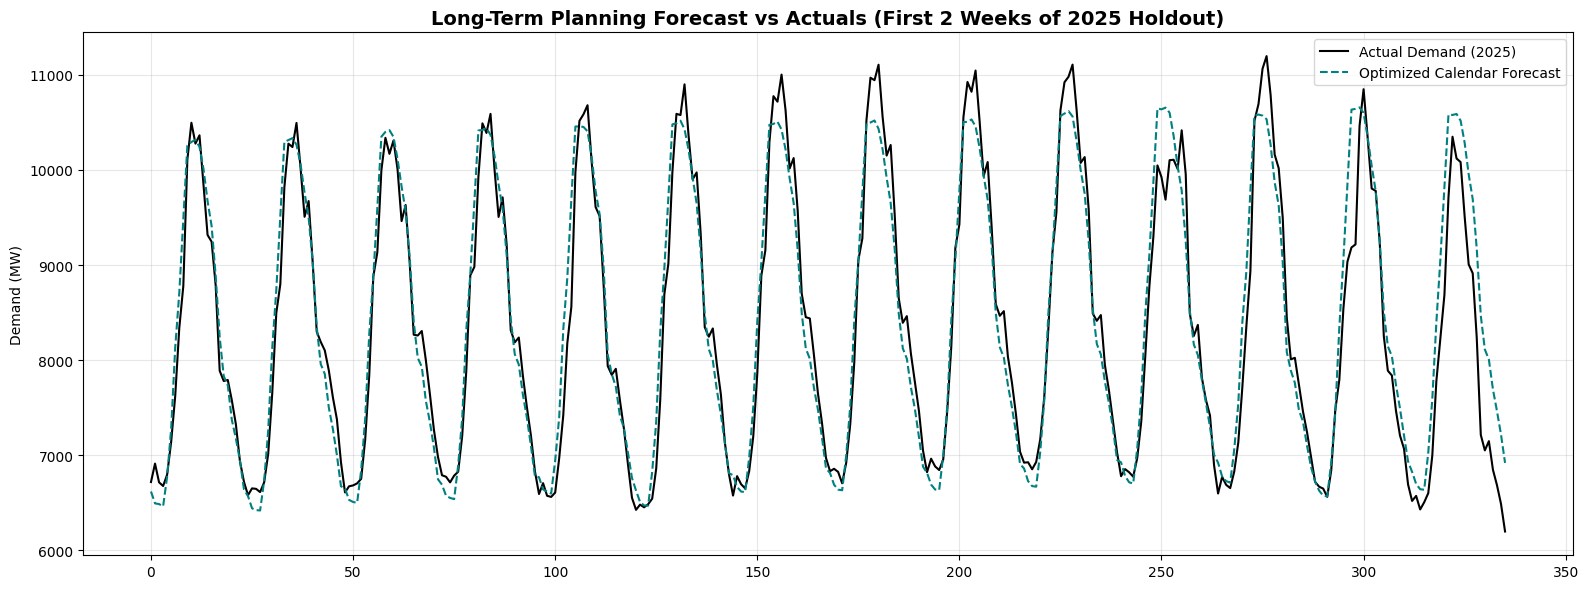

In [29]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("======================================================")
print("FINAL TRAINING, EXPORT & EVALUATION")
print("======================================================")

X_train_full_p = pd.concat([X_train_p, X_val_p])
y_train_full_p = pd.concat([y_train_p, y_val_p])

final_params = best_planner_params.copy()
final_params.update({'objective': 'regression_l1', 'verbose': -1})

planner_model = lgb.LGBMRegressor(**final_params)

callbacks = [
    lgb.early_stopping(stopping_rounds=100, verbose=True),
    lgb.log_evaluation(period=200)
]

print("[INFO] Training Final Planning Model...")
planner_model.fit(
    X_train_full_p, y_train_full_p, 
    eval_set=[(X_train_full_p, y_train_full_p), (X_test_p, y_test_p)], 
    categorical_feature=categorical_features,
    callbacks=callbacks
)

os.makedirs('../models', exist_ok=True)
model_path = '../models/planner_model.pkl'
mapping_path = '../models/state_mapping.pkl'

joblib.dump(planner_model, model_path)
joblib.dump(state_to_idx, mapping_path)
print(f"\n[SUCCESS] Model saved to: {model_path}")

preds_p = np.expm1(planner_model.predict(X_test_p)) # EXPM1 IS BACK
true_p = np.expm1(y_test_p).values

print("\n--- PLANNING MODEL METRICS (2025 HOLDOUT) ---")
print(f"MAE:  {mean_absolute_error(true_p, preds_p):.2f} MW")
print(f"RMSE: {np.sqrt(mean_squared_error(true_p, preds_p)):.2f} MW")
print(f"MAPE: {safe_mape(true_p, preds_p):.2f} %")
print(f"R2:   {r2_score(true_p, preds_p):.4f}")

plot_slice = 336
plt.figure(figsize=(16, 6))
plt.plot(true_p[:plot_slice], label='Actual Demand (2025)', color='black')
plt.plot(preds_p[:plot_slice], label='Optimized Calendar Forecast', color='teal', linestyle='--')
plt.title('Long-Term Planning Forecast vs Actuals (First 2 Weeks of 2025 Holdout)', fontsize=14, fontweight='bold')
plt.ylabel('Demand (MW)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [30]:
print("======================================================")
print("INFERENCE API (READY FOR BACKEND)")
print("======================================================")

class ProductionEnergyPlanner:
    def __init__(self, model_path='../models/planner_model.pkl', mapping_path='../models/state_mapping.pkl'):
        self.model = joblib.load(model_path)
        self.state_to_idx = joblib.load(mapping_path)
        self.states = list(self.state_to_idx.keys())
        
        self.features = [
            'state_encoded', 'year', 'month', 'day', 'hour', 'dayofweek', 'dayofyear', 
            'weekofyear', 'quarter', 'is_weekend', 'is_holiday', 'is_peak', 'is_solar',
            'hour_sin', 'hour_cos', 'month_sin', 'month_cos', 
            'dayofweek_sin', 'dayofweek_cos', 'dayofyear_sin', 'dayofyear_cos'
        ]

    def forecast(self, state, target_date_str, target_hour=None):
        if state not in self.states:
            raise ValueError(f"State '{state}' not found.")
            
        target_date = pd.to_datetime(target_date_str)
        year = target_date.year
        
        date_rng = pd.date_range(start=f"{year}-01-01 00:00:00", end=f"{year}-12-31 23:00:00", freq='h')
        df_future = pd.DataFrame({'datetime': date_rng})
        
        df_future['state_encoded'] = self.state_to_idx[state]
        df_future['year'] = df_future['datetime'].dt.year
        df_future['month'] = df_future['datetime'].dt.month
        df_future['day'] = df_future['datetime'].dt.day
        df_future['hour'] = df_future['datetime'].dt.hour
        df_future['dayofweek'] = df_future['datetime'].dt.dayofweek
        df_future['dayofyear'] = df_future['datetime'].dt.dayofyear
        df_future['weekofyear'] = df_future['datetime'].dt.isocalendar().week.astype(int)
        df_future['quarter'] = df_future['datetime'].dt.quarter
        df_future['is_weekend'] = (df_future['dayofweek'] >= 5).astype(int)
        
        df_future['is_peak'] = df_future['hour'].isin([18, 19, 20, 21, 22]).astype(int)
        df_future['is_solar'] = df_future['hour'].isin([10, 11, 12, 13, 14, 15, 16, 17]).astype(int)
        
        df_future['hour_sin'] = np.sin(2 * np.pi * df_future['hour'] / 23.0)
        df_future['hour_cos'] = np.cos(2 * np.pi * df_future['hour'] / 23.0)
        df_future['month_sin'] = np.sin(2 * np.pi * df_future['month'] / 12.0)
        df_future['month_cos'] = np.cos(2 * np.pi * df_future['month'] / 12.0)
        df_future['dayofweek_sin'] = np.sin(2 * np.pi * df_future['dayofweek'] / 6.0)
        df_future['dayofweek_cos'] = np.cos(2 * np.pi * df_future['dayofweek'] / 6.0)
        df_future['dayofyear_sin'] = np.sin(2 * np.pi * df_future['dayofyear'] / 365.25)
        df_future['dayofyear_cos'] = np.cos(2 * np.pi * df_future['dayofyear'] / 365.25)
        
        in_holidays = holidays.India(years=[year])
        df_future['is_holiday'] = df_future['datetime'].dt.date.apply(lambda x: 1 if x in in_holidays else 0)
        
        X_future = df_future[self.features]
        
        df_future['predicted_demand_mw'] = np.expm1(self.model.predict(X_future)) 
        
        hourly_val = None
        if target_hour is not None:
            mask_hour = (df_future['datetime'].dt.date == target_date.date()) & (df_future['hour'] == target_hour)
            if not df_future[mask_hour].empty: hourly_val = df_future.loc[mask_hour, 'predicted_demand_mw'].values[0]
        
        mask_day = df_future['datetime'].dt.date == target_date.date()
        daily_total = df_future.loc[mask_day, 'predicted_demand_mw'].sum()
        
        mask_week = df_future['datetime'].dt.isocalendar().week == target_date.isocalendar().week
        weekly_total = df_future.loc[mask_week, 'predicted_demand_mw'].sum()
        
        mask_month = df_future['month'] == target_date.month
        monthly_total = df_future.loc[mask_month, 'predicted_demand_mw'].sum()
        
        yearly_total = df_future['predicted_demand_mw'].sum()
        
        print("\n" + "="*60)
        print(f"⚡ ENERGY DEMAND FORECAST REPORT ⚡")
        print(f"📍 State: {state} | 📅 Date: {target_date.strftime('%B %d, %Y')}")
        print("="*60)
        if target_hour is not None: print(f"🕒 Specific Hour ({target_hour:02d}:00): {hourly_val:,.2f} MW\n" + "-"*40)
        print(f"📆 Total DAY:   {daily_total:,.2f} MW")
        print(f"📅 Total WEEK:  {weekly_total:,.2f} MW")
        print(f"🗓️ Total MONTH: {monthly_total:,.2f} MW")
        print(f"🌍 Total YEAR:  {yearly_total:,.2f} MW")
        print("="*60)
        
        return df_future

# Test the API
api = ProductionEnergyPlanner()
_ = api.forecast(state="Maharashtra", target_date_str="2026-11-08", target_hour=18)

🔮 4. INFERENCE API (READY FOR BACKEND)

⚡ ENERGY DEMAND FORECAST REPORT ⚡
📍 State: Maharashtra | 📅 Date: November 08, 2026
🕒 Specific Hour (18:00): 23,316.98 MW
----------------------------------------
📆 Total DAY:   542,433.32 MW
📅 Total WEEK:  3,868,264.20 MW
🗓️ Total MONTH: 16,824,953.01 MW
🌍 Total YEAR:  206,315,060.92 MW
